# Brecha digital y desempeño en Saber 11
## Herramientas de Big Data — Proyecto final
**Universidad de La Sabana — Facultad de Ingeniería**

### Pregunta
¿Qué tanto explica el **acceso a internet fijo del municipio** el puntaje del Saber 11, una vez se tienen en cuenta las condiciones del hogar del estudiante (estrato, educación de los padres, internet y computador en casa)?

### Datos (datos.gov.co, API Socrata)
| Fuente | Dataset | Uso |
|---|---|---|
| ICFES — Resultados únicos Saber 11 | `kgxf-xxbe` | Estudiantes 2017, 2019, 2020-1 y 2022 |
| ICFES — Saber 11 2020-2 | `rnvb-vnyh` | Falta en el consolidado |
| MinTIC — Internet fijo: accesos por tecnología y segmento | `n48w-gutb` | Indicadores municipales de conectividad |
| MinTIC — Accesos fijos por municipio y población | `tvzi-ba2g` | Población DANE 2023 y nombres |
| MinSalud — DIVIPOLA municipios | `pqwj-3fi4` | Coordenadas para los mapas |

### Arquitectura (Medallion) y herramientas del curso
```
 API datos.gov.co ──► BRONZE (Parquet crudo, particionado por año)        pandas + pyarrow
                        │
                        ▼
                     SILVER (limpio, deduplicado, enriquecido)             PySpark: broadcast joins, AQE,
                        │                                                  persist, partitionBy, salting
                        ▼
                     GOLD (municipio × año, tablas de brecha)             PySpark + DuckDB (SQL OLAP)
                        │
        ┌───────────────┼──────────────────┬──────────────────┐
        ▼               ▼                  ▼                  ▼
   EDA (Polars)   Mapas (Folium)   MongoDB   Modelos (scikit-learn + Spark MLlib)
```
Cada paso pesado se mide con el decorador `@track_performance` (*"Measure, don't estimate"*) y al final hay un tablero de observabilidad.

### Cómo ejecutarlo
1. Python 3.10–3.13 (PySpark aún no soporta 3.14) y **Java 17 o superior**.
2. `pip install -r requirements.txt`
3. El cuaderno debe estar en la misma carpeta que `saber11_internet.py`.
4. La primera ejecución descarga ~3,3 M de filas de la API (unos 20–25 minutos); las siguientes usan `datos/cache` y el cuaderno completo corre en ~3 minutos.
5. MongoDB: usa Atlas si hay un `.env` con `MONGO_CONN_STRING=...`; si no, un Mongo local en Docker (`docker start pbd-mongo`).

## 0. Configuración

In [1]:
import os, sys, time, shutil, subprocess, warnings
from functools import wraps
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import duckdb
import psutil
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import HeatMap
from branca.colormap import LinearColormap
from IPython.display import display

import saber11_internet as sb   # funciones de descarga y limpieza del script del proyecto

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

ANIOS = [2017, 2019, 2020, 2022]
TRIMESTRE_INTERNET = 3            # el examen de calendario A se presenta en ago-sep

LAKE = Path("datos/lake")
BRONZE, SILVER, GOLD = LAKE / "bronze", LAKE / "silver", LAKE / "gold"
FIGS = Path("resultados")
for p in (BRONZE, SILVER, GOLD, FIGS):
    p.mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(FIGS / f"{nombre}.png", dpi=150, bbox_inches="tight")

### 0.1 Observabilidad: decorador `@track_performance`
Igual que en la Sesión 5: mide tiempo de pared y cambio de RAM de cada paso y lo guarda en `pipeline_timings` para el tablero final.
Como Spark es *lazy*, cada función decorada debe terminar en una **acción** (`count`, `collect`, `write`, `toPandas`).

In [2]:
pipeline_timings = {}

def track_performance(step_name):
    def decorator(func):
        @wraps(func)
        def wrapper(*args, **kwargs):
            mem_before = psutil.virtual_memory().used / 1024**3
            t0 = time.perf_counter()
            result = func(*args, **kwargs)
            elapsed = time.perf_counter() - t0
            mem_delta = psutil.virtual_memory().used / 1024**3 - mem_before
            pipeline_timings[step_name] = elapsed
            print(f"[METRIC] {step_name:38s} | Time: {elapsed:7.2f}s | RAM delta: {mem_delta:+.2f} GB")
            return result
        return wrapper
    return decorator

### 0.2 `SparkSession` local
Spark corre en modo `local[*]` (todos los núcleos del computador). Las mismas configuraciones de la Sesión 5:
- **AQE** (`spark.sql.adaptive.enabled`) para reoptimizar el plan en tiempo de ejecución.
- `spark.sql.shuffle.partitions = 16`: las 200 por defecto son para clústeres; en un portátil generan sobrecosto.

In [3]:
# Spark necesita que driver y workers usen el mismo Python, y Java 17+
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
if "JAVA_HOME" not in os.environ and sys.platform == "darwin":
    try:
        os.environ["JAVA_HOME"] = subprocess.check_output(["/usr/libexec/java_home", "-v", "17+"]).decode().strip()
    except Exception:
        pass

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import broadcast
from pyspark.storagelevel import StorageLevel

spark = (SparkSession.builder
         .appName("Saber11_x_Internet_Medallion")
         .master("local[*]")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.adaptive.enabled", "true")
         .config("spark.sql.adaptive.coalescePartitions.enabled", "true")
         .config("spark.sql.shuffle.partitions", "16")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

print(f"Spark {spark.version} | paralelismo: {spark.sparkContext.defaultParallelism} núcleos | "
      f"RAM: {psutil.virtual_memory().total / 1024**3:.0f} GB | Spark UI: {spark.sparkContext.uiWebUrl}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/21 10:19:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0 | paralelismo: 10 núcleos | RAM: 16 GB | Spark UI: http://172.21.25.81:4040


## 1. Capa Bronze — ingesta desde la API
La Bronze guarda los datos **tal como llegan** (todo como texto, con duplicados incluidos) para poder auditar y reprocesar.

- **Saber 11**: se descarga paginado (50.000 filas por petición) solo con las columnas necesarias (*column pruning* en la fuente).
- **Internet**: la API hace el `GROUP BY` municipio antes de descargar (*server-side aggregation*, como los *aggregation pipelines* de MongoDB): baja ~1.100 filas por año en vez de ~190.000.

Lo descargado queda en `datos/cache`, así que solo se baja una vez.

In [4]:
def saber_crudo(anio):
    sel = ",".join(sb.COLS_SABER)
    per = ",".join(f"'{p}'" for p in sb.PERIODOS[anio])
    df = sb.cache(f"saber11_{anio}", lambda: sb.descargar_paginado(sb.DS_SABER, sel, f"periodo in({per})"))
    if anio == 2020:
        df2 = sb.cache("saber11_2020_2", lambda: sb.descargar_paginado(sb.DS_SABER_2020_2, sel, "1=1"))
        df = pd.concat([df, df2], ignore_index=True)
    return df.assign(anio=anio)

@track_performance("1_ingesta_api_o_cache")
def ingestar():
    saber = pd.concat([saber_crudo(a) for a in ANIOS], ignore_index=True)
    internet = pd.concat([sb.bajar_internet(a, TRIMESTRE_INTERNET, False) for a in ANIOS], ignore_index=True)
    poblacion = sb.bajar_poblacion(False)
    nombres = sb.cache("nombres_municipios", lambda: sb.soql(sb.DS_POBLACION, {
        "$select": "codigo_dane_municipio, municipio, departamento",
        "$where": "anno=2023 AND trimestre=4", "$limit": 5000}))
    coords = sb.cache("coordenadas_municipios", lambda: sb.soql("pqwj-3fi4", {
        "$select": "idmupio, mpiolatitud, mpiolongitud", "$limit": 5000}))
    return saber, internet, poblacion, nombres, coords

saber_raw, internet_raw, poblacion_raw, nombres_raw, coords_raw = ingestar()
print(f"Saber 11 crudo: {len(saber_raw):,} filas x {saber_raw.shape[1]} columnas")
saber_raw.groupby("anio").size().rename("filas_crudas").to_frame().T

Internet 2017-T3: agregando por municipio en la API
Internet 2019-T3: agregando por municipio en la API
Internet 2020-T3: agregando por municipio en la API
Internet 2022-T3: agregando por municipio en la API
Poblacion DANE 2023 (la que trae MinTIC)
[METRIC] 1_ingesta_api_o_cache                  | Time:    2.45s | RAM delta: +0.28 GB
Saber 11 crudo: 3,276,616 filas x 14 columnas


anio,2017,2019,2020,2022
filas_crudas,561287,1109085,520307,1085937


### 1.1 Persistencia en Parquet particionado por año
Escribimos la Bronze en **Parquet** con `partition_cols=["anio"]` (una carpeta `anio=XXXX` por año) y comparamos con CSV, como en el Workshop 1.

In [5]:
@track_performance("1_escribir_bronze_parquet")
def escribir_bronze():
    shutil.rmtree(BRONZE, ignore_errors=True); BRONZE.mkdir(parents=True)
    saber_raw.to_parquet(BRONZE / "saber11", partition_cols=["anio"], index=False)
    internet_raw.to_parquet(BRONZE / "internet_municipal.parquet", index=False)
    poblacion_raw.to_parquet(BRONZE / "poblacion_2023.parquet", index=False)
    nombres_raw.to_parquet(BRONZE / "nombres_municipios.parquet", index=False)
    coords_raw.to_parquet(BRONZE / "coordenadas_municipios.parquet", index=False)

escribir_bronze()

def tam_mb(ruta):
    ruta = Path(ruta)
    if ruta.is_file():
        return ruta.stat().st_size / 1024**2
    return sum(f.stat().st_size for f in ruta.rglob("*") if f.is_file()) / 1024**2

# Comparación de formatos con un año (2022)
tmp_csv = LAKE / "tmp_saber11_2022.csv"
saber_raw[saber_raw.anio == 2022].to_csv(tmp_csv, index=False)

@track_performance("1_leer_2_columnas_csv")
def leer_csv():
    return pd.read_csv(tmp_csv, usecols=["punt_global", "fami_estratovivienda"])

@track_performance("1_leer_2_columnas_parquet")
def leer_parquet():
    return pd.read_parquet(BRONZE / "saber11" / "anio=2022", columns=["punt_global", "fami_estratovivienda"])

leer_csv(); leer_parquet()
comp = pd.DataFrame({
    "formato": ["CSV", "CSV comprimido (gzip, caché)", "Parquet (snappy)"],
    "tamaño_MB": [tam_mb(tmp_csv), tam_mb("datos/cache/saber11_2022.csv.gz"), tam_mb(BRONZE / "saber11" / "anio=2022")],
})
comp["vs_CSV_%"] = 100 * (1 - comp["tamaño_MB"] / comp["tamaño_MB"].iloc[0])
tmp_csv.unlink()
display(comp)
print(f"Lectura de 2 columnas -> CSV: {pipeline_timings['1_leer_2_columnas_csv']:.2f}s | "
      f"Parquet: {pipeline_timings['1_leer_2_columnas_parquet']:.2f}s "
      f"({pipeline_timings['1_leer_2_columnas_csv'] / pipeline_timings['1_leer_2_columnas_parquet']:.0f}x más rápido)")

[METRIC] 1_escribir_bronze_parquet              | Time:    0.80s | RAM delta: +0.01 GB


[METRIC] 1_leer_2_columnas_csv                  | Time:    0.10s | RAM delta: -0.00 GB
[METRIC] 1_leer_2_columnas_parquet              | Time:    0.01s | RAM delta: +0.00 GB


,formato,tamaño_MB,vs_CSV_%
0,CSV,134.93,0.00
1,"CSV comprimido (gzip, caché)",14.14,89.52
2,Parquet (snappy),16.24,87.97


Lectura de 2 columnas -> CSV: 0.10s | Parquet: 0.01s (14x más rápido)


Parquet es columnar: para leer 2 columnas no tiene que recorrer las otras 12 (*column pruning*), y además comprime por columna.

## 2. Capa Silver — limpieza y enriquecimiento con PySpark
Pasos:
1. Leer la Bronze (Spark descubre la partición `anio` sola).
2. **Deduplicar**: el consolidado del ICFES trae a cada estudiante **dos veces** en 2019 y 2022.
3. Traducir categorías a números con **tablas de dimensión** (estrato, educación de los padres) usando **broadcast joins**.
4. Calcular los indicadores de internet por municipio y cruzarlos con los estudiantes (otro broadcast join).
5. Guardar particionado por año.

In [6]:
bronze = spark.read.parquet(str(BRONZE / "saber11"))
bronze.printSchema()

@track_performance("2_conteo_bronze")
def conteos_bronze():
    return (bronze.groupBy("anio")
            .agg(F.count("*").alias("filas"), F.countDistinct("estu_consecutivo").alias("estudiantes_unicos"))
            .orderBy("anio").toPandas())

dup = conteos_bronze()
dup["duplicados"] = dup["filas"] - dup["estudiantes_unicos"]
dup

root
 |-- periodo: string (nullable = true)
 |-- estu_consecutivo: string (nullable = true)
 |-- estu_cod_reside_mcpio: string (nullable = true)
 |-- cole_cod_mcpio_ubicacion: string (nullable = true)
 |-- punt_global: string (nullable = true)
 |-- fami_estratovivienda: string (nullable = true)
 |-- fami_educacionmadre: string (nullable = true)
 |-- fami_educacionpadre: string (nullable = true)
 |-- fami_tieneinternet: string (nullable = true)
 |-- fami_tienecomputador: string (nullable = true)
 |-- cole_naturaleza: string (nullable = true)
 |-- cole_area_ubicacion: string (nullable = true)
 |-- estu_genero: string (nullable = true)
 |-- anio: integer (nullable = true)



[METRIC] 2_conteo_bronze                        | Time:    3.33s | RAM delta: -0.43 GB


,anio,filas,estudiantes_unicos,duplicados
0,2017,561287,559279,2008
1,2019,1109085,558751,550334
2,2020,520307,520307,0
3,2022,1085937,552841,533096


### 2.1 Tablas de dimensión
Las respuestas socioeconómicas vienen como texto. En vez de `if/else` fila por fila, las traducimos con **tablas lookup** pequeñas (estrato → número, nivel educativo → años de estudio aproximados).

In [7]:
df_estrato = spark.createDataFrame([(k, float(v)) for k, v in sb.ESTRATO.items()],
                                   ["fami_estratovivienda", "estrato"])
df_educ = spark.createDataFrame([(k, float(v)) for k, v in sb.EDUCACION.items()],
                                ["nivel", "anios_estudio"])
df_educ_madre = df_educ.withColumnRenamed("nivel", "fami_educacionmadre").withColumnRenamed("anios_estudio", "educ_madre")
df_educ_padre = df_educ.withColumnRenamed("nivel", "fami_educacionpadre").withColumnRenamed("anios_estudio", "educ_padre")
df_educ.show(truncate=False)

+------------------------------------+-------------+
|nivel                               |anios_estudio|
+------------------------------------+-------------+
|Ninguno                             |0.0          |
|Primaria incompleta                 |3.0          |
|Primaria completa                   |5.0          |
|Secundaria (Bachillerato) incompleta|8.0          |
|Secundaria (Bachillerato) completa  |11.0         |
|Técnica o tecnológica incompleta    |12.0         |
|Técnica o tecnológica completa      |14.0         |
|Educación profesional incompleta    |13.5         |
|Educación profesional completa      |16.0         |
|Postgrado                           |18.0         |
+------------------------------------+-------------+



### 2.2 Shuffle Sort-Merge Join vs. Broadcast Hash Join
Comparamos las dos estrategias sobre la tabla de estudiantes deduplicada (~2,2 M filas) y la dimensión de estrato (7 filas):
- **SSMJ**: reparte *ambas* tablas por la llave (`Exchange hashpartitioning`) y las ordena → shuffle de los 2,2 M de filas.
- **BHJ**: copia la tabla pequeña a cada executor → **cero shuffle** de la tabla grande.

In [8]:
estudiantes = bronze.dropDuplicates(["estu_consecutivo"])

# --- Estrategia A: forzar Sort-Merge Join ---
umbral_original = spark.conf.get("spark.sql.autoBroadcastJoinThreshold")
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
join_ssmj = estudiantes.join(df_estrato, "fami_estratovivienda", "left")
print("=== PLAN A: SHUFFLE SORT-MERGE JOIN ===")
join_ssmj.explain("simple")

@track_performance("2a_join_sort_merge")
def correr_ssmj():
    return join_ssmj.count()
correr_ssmj()
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", umbral_original)

# --- Estrategia B: broadcast explícito ---
join_bhj = estudiantes.join(broadcast(df_estrato), "fami_estratovivienda", "left")
print("\n=== PLAN B: BROADCAST HASH JOIN ===")
join_bhj.explain("simple")

@track_performance("2b_join_broadcast")
def correr_bhj():
    return join_bhj.count()
correr_bhj()

print(f"\n>>> Broadcast join: {pipeline_timings['2a_join_sort_merge'] / pipeline_timings['2b_join_broadcast']:.2f}x más rápido")

=== PLAN A: SHUFFLE SORT-MERGE JOIN ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [fami_estratovivienda#66, periodo#58, estu_consecutivo#1, estu_cod_reside_mcpio#60, cole_cod_mcpio_ubicacion#62, punt_global#64, fami_educacionmadre#68, fami_educacionpadre#70, fami_tieneinternet#72, fami_tienecomputador#74, cole_naturaleza#76, cole_area_ubicacion#78, estu_genero#80, anio#82, estrato#43]
   +- SortMergeJoin [fami_estratovivienda#66], [fami_estratovivienda#42], LeftOuter
      :- Sort [fami_estratovivienda#66 ASC NULLS FIRST], false, 0
      :  +- Exchange hashpartitioning(fami_estratovivienda#66, 16), ENSURE_REQUIREMENTS, [plan_id=191]
      :     +- SortAggregate(key=[estu_consecutivo#1], functions=[first(periodo#0, false), first(estu_cod_reside_mcpio#2, false), first(cole_cod_mcpio_ubicacion#3, false), first(punt_global#4, false), first(fami_estratovivienda#5, false), first(fami_educacionmadre#6, false), first(fami_educacionpadre#7, false), first(fami_tieneinter

[METRIC] 2a_join_sort_merge                     | Time:    3.15s | RAM delta: -0.23 GB

=== PLAN B: BROADCAST HASH JOIN ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [fami_estratovivienda#201, periodo#193, estu_consecutivo#1, estu_cod_reside_mcpio#195, cole_cod_mcpio_ubicacion#197, punt_global#199, fami_educacionmadre#203, fami_educacionpadre#205, fami_tieneinternet#207, fami_tienecomputador#209, cole_naturaleza#211, cole_area_ubicacion#213, estu_genero#215, anio#217, estrato#43]
   +- BroadcastHashJoin [fami_estratovivienda#201], [fami_estratovivienda#42], LeftOuter, BuildRight, false, false
      :- SortAggregate(key=[estu_consecutivo#1], functions=[first(periodo#0, false), first(estu_cod_reside_mcpio#2, false), first(cole_cod_mcpio_ubicacion#3, false), first(punt_global#4, false), first(fami_estratovivienda#5, false), first(fami_educacionmadre#6, false), first(fami_educacionpadre#7, false), first(fami_tieneinternet#8, false), first(fami_tienecomputador#9, fa

[METRIC] 2b_join_broadcast                      | Time:    1.30s | RAM delta: -0.17 GB

>>> Broadcast join: 2.43x más rápido


En el plan A aparecen `SortMergeJoin`, `Sort` y dos `Exchange hashpartitioning` (uno por tabla); en el B, `BroadcastHashJoin` + `BroadcastExchange` y la tabla grande **no se mueve**.
Ambos incluyen un `Exchange` previo que viene del `dropDuplicates` (deduplicar sí obliga a reagrupar por estudiante).

### 2.3 Indicadores municipales de internet (Spark)
Por municipio y año, a partir de los agregados que entregó la API:

| Indicador | Definición |
|---|---|
| `penetracion` | accesos fijos por cada 100 habitantes (población DANE 2023) |
| `pct_fibra` | % de accesos por fibra óptica (FTTx) |
| `vel_prom_mbps` | velocidad de bajada promedio, ponderada por accesos (*) |
| `pct_25mbps` | % de accesos con 25 Mbps o más |
| `pct_sat_inal` | % de accesos satelitales o inalámbricos (WiFi, WiMAX, otros) |

(*) **Limpieza en la fuente**: algunos proveedores reportan la velocidad en kbps en una columna de Mbps (p. ej. `12288` = 12 Mbps, `21300` en Belalcázar). Sin corregir, municipios pequeños aparecían con velocidades promedio de 200.000 Mbps. La consulta a la API trata todo valor > 1.000 Mbps como kbps y lo divide entre 1.024.

In [9]:
def cod5(col):
    # Código DANE a 5 dígitos con el cero inicial ('5001' -> '05001')
    c = F.regexp_replace(F.trim(col.cast("string")), r"\.0$", "")
    return F.when(c.rlike(r"^\d{4,5}$"), F.lpad(c, 5, "0"))

net = spark.createDataFrame(internet_raw.drop(columns=["anio"]).assign(anio=internet_raw["anio"].astype(int)))
pob = (spark.createDataFrame(poblacion_raw.dropna())
       .withColumnRenamed("cod_mcpio", "cod_mcpio_pob"))

acc = lambda c: F.col(c).cast("double")
internet_mun = (net
    .withColumn("cod_mcpio", cod5(F.col("cod_municipio")))
    .join(broadcast(pob), F.col("cod_mcpio") == F.col("cod_mcpio_pob"), "left")
    .select("cod_mcpio", "anio",
            acc("accesos").alias("accesos"), F.col("poblacion"),
            (100 * acc("accesos") / F.col("poblacion")).alias("penetracion"),
            (100 * acc("acc_fibra") / acc("accesos")).alias("pct_fibra"),
            (acc("acc_x_vel") / acc("accesos")).alias("vel_prom_mbps"),
            (100 * acc("acc_25mbps") / acc("accesos")).alias("pct_25mbps"),
            (100 * acc("acc_sat_inal") / acc("accesos")).alias("pct_sat_inal"))
    .filter(F.col("cod_mcpio").isNotNull()))

internet_mun.groupBy("anio").agg(
    F.count("*").alias("municipios"),
    F.round(F.expr("percentile_approx(penetracion, 0.5)"), 2).alias("penetracion_mediana"),
    F.round(F.avg("pct_fibra"), 1).alias("pct_fibra_prom"),
    F.round(F.expr("percentile_approx(vel_prom_mbps, 0.5)"), 1).alias("vel_mediana_mbps"),
).orderBy("anio").show()

+----+----------+-------------------+--------------+----------------+
|anio|municipios|penetracion_mediana|pct_fibra_prom|vel_mediana_mbps|
+----+----------+-------------------+--------------+----------------+
|2017|      1105|               2.01|          43.1|             3.2|
|2019|      1115|               2.12|          46.2|             6.4|
|2020|      1112|               1.83|          36.2|            11.0|
|2022|      1117|               3.31|          50.4|            15.2|
+----+----------+-------------------+--------------+----------------+



### 2.4 Construcción de la Silver
Un solo plan lazy con tres broadcast joins (estrato, educación madre, educación padre) y el join con internet municipal (≈4.400 filas, también broadcast). Luego `persist(MEMORY_AND_DISK)` porque la Silver se reutiliza muchas veces.

In [10]:
si_no = lambda c: F.when(F.col(c) == "Si", 1.0).when(F.col(c) == "No", 0.0)

silver = (estudiantes
    .join(broadcast(df_estrato), "fami_estratovivienda", "left")
    .join(broadcast(df_educ_madre), "fami_educacionmadre", "left")
    .join(broadcast(df_educ_padre), "fami_educacionpadre", "left")
    .withColumn("cod_mcpio", cod5(F.col("estu_cod_reside_mcpio")))
    .withColumn("cod_mcpio_colegio", cod5(F.col("cole_cod_mcpio_ubicacion")))
    .withColumn("punt_global", F.col("punt_global").cast("double"))
    .withColumn("sin_estrato", F.when(F.col("estrato").isNotNull(), (F.col("estrato") == 0).cast("double")))
    .withColumn("internet_casa", si_no("fami_tieneinternet"))
    .withColumn("computador_casa", si_no("fami_tienecomputador"))
    .withColumn("colegio_oficial", F.when(F.col("cole_naturaleza").isNotNull(), (F.col("cole_naturaleza") == "OFICIAL").cast("double")))
    .withColumn("colegio_rural", F.when(F.col("cole_area_ubicacion").isNotNull(), (F.col("cole_area_ubicacion") == "RURAL").cast("double")))
    .withColumn("mujer", F.when(F.col("estu_genero") == "F", 1.0).when(F.col("estu_genero") == "M", 0.0))
    .filter(F.col("punt_global") > 0)          # descarta nulos y puntajes 0 (exámenes anulados)
    .join(broadcast(internet_mun), ["cod_mcpio", "anio"], "left")
    .select("anio", "periodo", "estu_consecutivo", "cod_mcpio", "cod_mcpio_colegio", "punt_global",
            "estrato", "sin_estrato", "educ_madre", "educ_padre", "internet_casa", "computador_casa",
            "colegio_oficial", "colegio_rural", "mujer",
            "accesos", "poblacion", "penetracion", "pct_fibra", "vel_prom_mbps", "pct_25mbps", "pct_sat_inal"))

print("=== PLAN FÍSICO DE LA SILVER (busque BroadcastHashJoin x4) ===")
silver.explain("simple")

=== PLAN FÍSICO DE LA SILVER (busque BroadcastHashJoin x4) ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [anio#523, periodo#499, estu_consecutivo#1, cod_mcpio#489, cod_mcpio_colegio#490, punt_global#491, estrato#43, sin_estrato#492, educ_madre#47, educ_padre#49, internet_casa#493, computador_casa#494, colegio_oficial#495, colegio_rural#496, mujer#497, accesos#338, poblacion#335L, penetracion#339, pct_fibra#340, vel_prom_mbps#341, pct_25mbps#342, pct_sat_inal#343]
   +- BroadcastHashJoin [cod_mcpio#489, cast(anio#523 as bigint)], [cod_mcpio#337, anio#333L], LeftOuter, BuildRight, false, false
      :- Project [periodo#499, estu_consecutivo#1, cast(punt_global#505 as double) AS punt_global#491, anio#523, estrato#43, educ_madre#47, educ_padre#49, CASE WHEN RLIKE(regexp_replace(trim(estu_cod_reside_mcpio#501, None), \.0$, , 1), ^\d{4,5}$) THEN lpad(regexp_replace(trim(estu_cod_reside_mcpio#501, None), \.0$, , 1), 5, 0) END AS cod_mcpio#489, CASE WHEN RLIKE(regexp_r

### 2.5 Lazy evaluation y `persist()`
Sin persistencia, **cada acción** vuelve a leer Parquet, deduplicar y hacer los cuatro joins. Medimos tres consultas típicas del EDA antes y después de persistir.

In [11]:
def tres_consultas(df):
    a = df.groupBy("anio").agg(F.avg("punt_global")).collect()
    b = df.groupBy("estrato").agg(F.avg("punt_global")).collect()
    c = df.groupBy("anio", "internet_casa").count().collect()
    return a, b, c

@track_performance("3a_tres_consultas_sin_cache")
def sin_cache():
    return tres_consultas(silver)
sin_cache()

silver = silver.persist(StorageLevel.MEMORY_AND_DISK)

@track_performance("3b_materializar_persist")
def materializar():
    return silver.count()
n_silver = materializar()

@track_performance("3c_tres_consultas_con_persist")
def con_cache():
    return tres_consultas(silver)
con_cache()

print(f"\nSilver: {n_silver:,} estudiantes")
print(f">>> Con persist: {pipeline_timings['3a_tres_consultas_sin_cache'] / pipeline_timings['3c_tres_consultas_con_persist']:.1f}x más rápido")
print("\n=== Plan tras persist (aparece InMemoryTableScan) ===")
silver.groupBy("anio").count().explain("simple")

[METRIC] 3a_tres_consultas_sin_cache            | Time:   10.01s | RAM delta: -0.28 GB


[METRIC] 3b_materializar_persist                | Time:    6.78s | RAM delta: -0.12 GB


[METRIC] 3c_tres_consultas_con_persist          | Time:    0.76s | RAM delta: -0.01 GB

Silver: 2,191,087 estudiantes
>>> Con persist: 13.1x más rápido

=== Plan tras persist (aparece InMemoryTableScan) ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[anio#13], functions=[count(1)])
   +- Exchange hashpartitioning(anio#13, 16), ENSURE_REQUIREMENTS, [plan_id=3505]
      +- HashAggregate(keys=[anio#13], functions=[partial_count(1)])
         +- InMemoryTableScan [anio#13]
               +- InMemoryRelation [anio#13, periodo#0, estu_consecutivo#1, cod_mcpio#489, cod_mcpio_colegio#490, punt_global#491, estrato#43, sin_estrato#492, educ_madre#47, educ_padre#49, internet_casa#493, computador_casa#494, colegio_oficial#495, colegio_rural#496, mujer#497, accesos#338, poblacion#335L, penetracion#339, pct_fibra#340, vel_prom_mbps#341, pct_25mbps#342, pct_sat_inal#343], StorageLevel(disk, memory, 1 replicas)
                     +- AdaptiveSparkPlan isFinalPlan=tr

### 2.6 Calidad del cruce estudiante ↔ municipio

In [12]:
calidad = (silver.groupBy("anio").agg(
        F.count("*").alias("estudiantes"),
        F.round(100 * F.avg(F.col("penetracion").isNotNull().cast("int")), 2).alias("%_con_internet_municipal"),
        F.round(100 * F.avg(F.col("cod_mcpio").isNull().cast("int")), 2).alias("%_sin_codigo_municipio"),
        F.round(100 * F.avg(F.col("estrato").isNull().cast("int")), 1).alias("%_estrato_nulo"),
        F.round(100 * F.avg(F.col("educ_madre").isNull().cast("int")), 1).alias("%_educ_madre_nula"),
        F.round(100 * F.avg(F.col("internet_casa").isNull().cast("int")), 1).alias("%_internet_casa_nulo"))
    .orderBy("anio").toPandas())
calidad

,anio,estudiantes,%_con_internet_municipal,%_sin_codigo_municipio,%_estrato_nulo,%_educ_madre_nula,%_internet_casa_nulo
0,2017,559277,99.91,0.06,4.90,6.20,4.60
1,2019,558747,99.90,0.07,6.30,7.40,5.60
2,2020,520226,99.83,0.15,3.50,4.90,2.90
3,2022,552837,99.98,0.00,6.70,8.40,5.90


In [13]:
sin_cruce = (silver.filter(F.col("penetracion").isNull())
             .groupBy("anio", "cod_mcpio").count().orderBy(F.desc("count")).limit(10).toPandas())
print("Municipios que no cruzaron (más estudiantes primero):")
sin_cruce

Municipios que no cruzaron (más estudiantes primero):


,anio,cod_mcpio,count
0,2020,NaN,766
1,2019,NaN,378
2,2017,NaN,342
3,2019,99999,134
4,2020,27086,56
5,2017,91263,31
6,2022,27086,26
7,2017,91407,24
8,2020,99999,19
9,2017,91798,19


### 2.7 Escritura particionada y *partition pruning*
La Silver se guarda con `partitionBy("anio")`. Una consulta que filtra por año lee **solo esa carpeta** (`PartitionFilters` en el plan).

In [14]:
@track_performance("4a_escribir_silver_particionada")
def escribir_silver():
    silver.write.mode("overwrite").partitionBy("anio").parquet(str(SILVER / "estudiantes"))
escribir_silver()

print("--- Tamaño por partición (diagnóstico de skew) ---")
for d in sorted((SILVER / "estudiantes").glob("anio=*")):
    print(f"  {d.name:10s} -> {tam_mb(d):6.1f} MB")

[METRIC] 4a_escribir_silver_particionada        | Time:    2.30s | RAM delta: -0.09 GB
--- Tamaño por partición (diagnóstico de skew) ---
  anio=2017  ->   12.0 MB
  anio=2019  ->   12.1 MB
  anio=2020  ->   11.3 MB
  anio=2022  ->   12.1 MB


In [15]:
silver_2022 = (spark.read.parquet(str(SILVER / "estudiantes"))
               .filter(F.col("anio") == 2022)
               .select("punt_global", "estrato"))
print("Busque 'PartitionFilters: [isnotnull(anio), (anio = 2022)]' y un ReadSchema de solo 2 columnas:")
silver_2022.explain("formatted")

@track_performance("4b_leer_particion_2022")
def leer_2022():
    return silver_2022.agg(F.avg("punt_global")).collect()[0][0]
print(f"Puntaje promedio 2022: {leer_2022():.1f}")

Busque 'PartitionFilters: [isnotnull(anio), (anio = 2022)]' y un ReadSchema de solo 2 columnas:
== Physical Plan ==
* Project (3)
+- * ColumnarToRow (2)
   +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [punt_global#5546, estrato#5547, anio#5563]
Batched: true
Location: InMemoryFileIndex [file:/Users/juanpabloparrado/Desktop/PBD/datos/lake/silver/estudiantes]
PartitionFilters: [isnotnull(anio#5563), (anio#5563 = 2022)]
ReadSchema: struct<punt_global:double,estrato:double>

(2) ColumnarToRow [codegen id : 1]
Input [3]: [punt_global#5546, estrato#5547, anio#5563]

(3) Project [codegen id : 1]
Output [2]: [punt_global#5546, estrato#5547]
Input [3]: [punt_global#5546, estrato#5547, anio#5563]




[METRIC] 4b_leer_particion_2022                 | Time:    0.15s | RAM delta: +0.00 GB
Puntaje promedio 2022: 251.4


Las particiones por año quedan balanceadas (~550 mil estudiantes cada una): **no hay skew por año**.

### 2.8 Data skew por municipio y *salting*
Donde sí hay skew es en el municipio: Bogotá concentra una parte desproporcionada de los estudiantes, así que en un `groupBy("cod_mcpio")` un solo executor recibe mucho más trabajo.

In [16]:
top_mun = (silver.groupBy("cod_mcpio").count()
           .withColumn("pct", F.round(100 * F.col("count") / F.lit(n_silver), 2))
           .orderBy(F.desc("count")).limit(8).toPandas())
print(f"Municipios distintos: {silver.select('cod_mcpio').distinct().count():,}")
top_mun

Municipios distintos: 1,123


,cod_mcpio,count,pct
0,11001,341022,15.56
1,05001,112726,5.14
2,76001,86222,3.94
3,08001,66582,3.04
4,13001,54366,2.48
5,54001,34124,1.56
6,25754,31546,1.44
7,73001,28802,1.31


**Salting** en dos etapas: se agrega una sal aleatoria 0–9, se agrega parcialmente por `(municipio, año, sal)` — la llave caliente queda repartida en 10 tareas — y luego se combinan los parciales. Para promedios hay que llevar **suma y conteo** (no se pueden promediar promedios).

In [17]:
salted = (silver.withColumn("salt", (F.rand(seed=42) * 10).cast("int"))
          .groupBy("cod_mcpio", "anio", "salt")
          .agg(F.sum("punt_global").alias("s"), F.count("*").alias("n"))
          .groupBy("cod_mcpio", "anio")
          .agg((F.sum("s") / F.sum("n")).alias("punt_prom"), F.sum("n").alias("n")))
print("=== PLAN CON SALTING (dos HashAggregate + Exchange) ===")
salted.explain("simple")

directo = silver.groupBy("cod_mcpio", "anio").agg(F.avg("punt_global").alias("punt_prom"), F.count("*").alias("n"))

@track_performance("5a_groupby_municipio_directo")
def run_directo():
    return directo.toPandas()

@track_performance("5b_groupby_municipio_salting")
def run_salted():
    return salted.toPandas()

a, b = run_directo(), run_salted()
chk = a.merge(b, on=["cod_mcpio", "anio"], suffixes=("_directo", "_salting"))
print(f"\nMáxima diferencia en el promedio: {np.abs(chk.punt_prom_directo - chk.punt_prom_salting).max():.2e} "
      f"| conteos iguales: {(chk.n_directo == chk.n_salting).all()}")

=== PLAN CON SALTING (dos HashAggregate + Exchange) ===
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[cod_mcpio#489, anio#13], functions=[sum(s#6710), sum(n#6711L)])
   +- Exchange hashpartitioning(cod_mcpio#489, anio#13, 16), ENSURE_REQUIREMENTS, [plan_id=4036]
      +- HashAggregate(keys=[cod_mcpio#489, anio#13], functions=[partial_sum(s#6710), partial_sum(n#6711L)])
         +- HashAggregate(keys=[cod_mcpio#489, anio#13, salt#6709], functions=[sum(punt_global#491), count(1)])
            +- Exchange hashpartitioning(cod_mcpio#489, anio#13, salt#6709, 16), ENSURE_REQUIREMENTS, [plan_id=4032]
               +- HashAggregate(keys=[cod_mcpio#489, anio#13, salt#6709], functions=[partial_sum(punt_global#491), partial_count(1)])
                  +- Project [anio#13, cod_mcpio#489, punt_global#491, cast((rand(42) * 10.0) as int) AS salt#6709]
                     +- InMemoryTableScan [anio#13, cod_mcpio#489, punt_global#491]
                           +- In

[METRIC] 5a_groupby_municipio_directo           | Time:    0.52s | RAM delta: -0.01 GB


[METRIC] 5b_groupby_municipio_salting           | Time:    0.63s | RAM delta: +0.00 GB

Máxima diferencia en el promedio: 0.00e+00 | conteos iguales: True


Los resultados coinciden exactamente. En un computador local (y con AQE, que ya divide particiones sesgadas) el salting no siempre es más rápido: su beneficio aparece en clústeres con muchos executors y llaves mucho más calientes. Lo importante es la técnica y verificar que no cambia el resultado.

## 3. Capa Gold — tablas listas para consumo
- `gold/municipios`: una fila por municipio y año (puntaje, perfil del hogar, internet, nombre y coordenadas).
- `gold/brecha_estrato_internet`: puntaje promedio por año × estrato × internet en casa.

In [18]:
nombres = spark.createDataFrame(nombres_raw).select(
    cod5(F.col("codigo_dane_municipio")).alias("cod_mcpio"),
    F.initcap("municipio").alias("municipio"), F.initcap("departamento").alias("departamento"))
def corregir_coord(c, limite):
    # MinSalud trae algunas coordenadas sin punto decimal (Mariquita: lat 525, lon -74916667):
    # se divide por la potencia de 10 necesaria para que quede dentro de Colombia
    x = F.col(c).cast("double")
    return F.when(F.abs(x) > limite, x / F.pow(F.lit(10), F.ceil(F.log10(F.abs(x) / limite)))).otherwise(x)

coords = spark.createDataFrame(coords_raw).select(
    cod5(F.col("idmupio")).alias("cod_mcpio"),
    corregir_coord("mpiolatitud", 14).alias("lat"), corregir_coord("mpiolongitud", 82).alias("lon"))
print("Coordenadas corregidas:")
coords.filter(F.col("cod_mcpio") == "73443").show()

gold_mun = (silver.filter(F.col("cod_mcpio").isNotNull())
    .groupBy("cod_mcpio", "anio")
    .agg(F.count("*").alias("n_estudiantes"),
         F.avg("punt_global").alias("punt_global_prom"),
         F.avg("estrato").alias("estrato_prom"),
         F.avg("educ_madre").alias("educ_madre_prom"),
         (100 * F.avg("internet_casa")).alias("pct_internet_casa"),
         (100 * F.avg("computador_casa")).alias("pct_computador_casa"),
         (100 * F.avg("colegio_oficial")).alias("pct_colegio_oficial"),
         (100 * F.avg("colegio_rural")).alias("pct_colegio_rural"),
         *[F.first(c, ignorenulls=True).alias(c) for c in ["poblacion", "accesos"] + sb.VARS_MUNICIPIO])
    .join(broadcast(nombres), "cod_mcpio", "left")
    .join(broadcast(coords), "cod_mcpio", "left"))

gold_brecha = (silver.filter(F.col("estrato").isNotNull() & F.col("internet_casa").isNotNull())
    .groupBy("anio", "estrato", "internet_casa")
    .agg(F.count("*").alias("n"), F.avg("punt_global").alias("punt_prom")))

@track_performance("6_escribir_gold")
def escribir_gold():
    gold_mun.coalesce(1).write.mode("overwrite").parquet(str(GOLD / "municipios"))
    gold_brecha.coalesce(1).write.mode("overwrite").parquet(str(GOLD / "brecha_estrato_internet"))
escribir_gold()

mun = pd.read_parquet(GOLD / "municipios")
print(f"Gold municipios: {len(mun):,} filas (municipio-año) | sin coordenadas: {mun.lat.isna().sum()}")
mun.sort_values("n_estudiantes", ascending=False).head()

Coordenadas corregidas:
+---------+----+----------+
|cod_mcpio| lat|       lon|
+---------+----+----------+
|    73443|5.25|-74.916667|
+---------+----+----------+



[METRIC] 6_escribir_gold                        | Time:    1.73s | RAM delta: -0.01 GB
Gold municipios: 4,466 filas (municipio-año) | sin coordenadas: 5


,cod_mcpio,anio,n_estudiantes,punt_global_prom,estrato_prom,educ_madre_prom,pct_internet_casa,pct_computador_casa,pct_colegio_oficial,pct_colegio_rural,poblacion,accesos,penetracion,pct_fibra,vel_prom_mbps,pct_25mbps,pct_sat_inal,municipio,departamento,lat,lon
2775,11001,2017,92020,276.62,2.55,10.72,86.26,83.67,52.27,1.90,"7,907,281.00","1,807,827.00",22.86,24.18,8.81,6.52,0.07,"Bogotá, D.c.",Bogotá D.c.,4.31,-74.18
3118,11001,2019,86407,269.12,2.56,11.07,88.85,82.15,52.64,2.17,"7,907,281.00","1,915,409.00",24.22,29.12,20.01,20.89,0.36,"Bogotá, D.c.",Bogotá D.c.,4.31,-74.18
1701,11001,2022,81752,272.65,2.57,11.58,93.13,80.37,53.57,2.42,"7,907,281.00","2,261,755.00",28.60,46.13,154.66,85.86,0.29,"Bogotá, D.c.",Bogotá D.c.,4.31,-74.18
4298,11001,2020,80843,269.27,2.55,11.26,92.94,85.67,53.58,2.18,"7,907,281.00","2,069,115.00",26.17,33.77,40.41,64.69,0.54,"Bogotá, D.c.",Bogotá D.c.,4.31,-74.18
60,05001,2019,28505,250.14,2.48,10.24,82.13,71.18,63.35,4.48,"2,595,300.00","611,890.00",23.58,62.53,13.61,16.23,0.89,Medellín,Antioquia,6.26,-75.61


## 4. Consultas SQL analíticas con DuckDB (OLAP)
Como en la Sesión 2: DuckDB consulta los Parquet **directamente**, sin servidor ni carga previa. Es el motor ideal cuando los datos caben en un solo computador; Spark es para cuando no caben. Comparamos ambos con la misma consulta.

In [19]:
con = duckdb.connect()
SILVER_GLOB = str(SILVER / "estudiantes" / "**" / "*.parquet")
GOLD_MUN = str(GOLD / "municipios" / "*.parquet")

q_estrato = f'''
    SELECT anio, estrato, COUNT(*) AS n, ROUND(AVG(punt_global), 1) AS punt_prom
    FROM read_parquet('{SILVER_GLOB}', hive_partitioning = true)
    WHERE estrato IS NOT NULL
    GROUP BY anio, estrato ORDER BY anio, estrato'''

@track_performance("7a_duckdb_groupby_silver")
def duck():
    return con.sql(q_estrato).df()

@track_performance("7b_spark_groupby_silver")
def spark_q():
    return (spark.read.parquet(str(SILVER / "estudiantes")).filter(F.col("estrato").isNotNull())
            .groupBy("anio", "estrato").agg(F.count("*").alias("n"), F.round(F.avg("punt_global"), 1).alias("punt_prom"))
            .orderBy("anio", "estrato").toPandas())

res_duck = duck(); spark_q()
print("Puntaje promedio por estrato (pivot):")
res_duck.pivot(index="estrato", columns="anio", values="punt_prom").rename_axis(index="Estrato", columns="Año")

[METRIC] 7a_duckdb_groupby_silver               | Time:    0.02s | RAM delta: +0.00 GB


[METRIC] 7b_spark_groupby_silver                | Time:    0.43s | RAM delta: -0.01 GB
Puntaje promedio por estrato (pivot):


Año,2017,2019,2020,2022
Estrato,,,,
0.00,219.30,207.20,210.10,213.10
1.00,245.20,236.10,237.00,241.80
2.00,259.20,250.10,250.50,253.70
3.00,270.80,262.90,262.80,263.70
4.00,283.20,275.10,276.80,271.90
5.00,287.40,282.00,282.10,276.80
6.00,290.20,286.00,283.40,279.80


**Brecha por quintil de penetración de internet** (función de ventana `NTILE`), ponderando por número de estudiantes:

In [20]:
con.sql(f'''
    WITH q AS (
        SELECT *, NTILE(5) OVER (PARTITION BY anio ORDER BY penetracion) AS quintil
        FROM read_parquet('{GOLD_MUN}') WHERE penetracion IS NOT NULL AND n_estudiantes >= 30)
    SELECT anio, quintil,
           COUNT(*) AS municipios,
           ROUND(MIN(penetracion), 1) AS penetr_min, ROUND(MAX(penetracion), 1) AS penetr_max,
           ROUND(SUM(punt_global_prom * n_estudiantes) / SUM(n_estudiantes), 1) AS punt_prom,
           ROUND(SUM(pct_internet_casa * n_estudiantes) / SUM(n_estudiantes), 1) AS pct_internet_casa
    FROM q GROUP BY anio, quintil ORDER BY anio, quintil
''').df().pivot(index="quintil", columns="anio", values=["punt_prom", "penetr_max"])

punt_prom                      penetr_max                    
anio         2017   2019   2020   2022       2017  2019   2020   2022
quintil                                                              
1          228.40 217.40 220.60 220.90       0.60  0.70   0.40   0.80
2          238.90 230.60 227.70 230.50       1.50  1.60   1.20   2.60
3          240.30 230.70 231.60 232.30       2.80  3.10   3.50   5.00
4          242.30 231.60 235.00 237.70       5.30  6.50   7.50  10.00
5          263.60 255.60 257.30 260.30      31.50 38.00 100.30 121.40

**Departamentos 2022**: puntaje y conectividad (ponderados por estudiantes):

In [21]:
deptos = con.sql(f'''
    SELECT departamento,
           SUM(n_estudiantes) AS estudiantes,
           ROUND(SUM(punt_global_prom * n_estudiantes) / SUM(n_estudiantes), 1) AS punt_prom,
           ROUND(100 * SUM(accesos) / SUM(poblacion), 1) AS penetracion,
           ROUND(SUM(pct_internet_casa * n_estudiantes) / SUM(n_estudiantes), 1) AS pct_internet_casa
    FROM read_parquet('{GOLD_MUN}')
    WHERE anio = 2022 AND departamento IS NOT NULL
    GROUP BY departamento ORDER BY punt_prom DESC''').df()
pd.concat([deptos.head(6), deptos.tail(6)])

,departamento,estudiantes,punt_prom,penetracion,pct_internet_casa
0,Bogotá D.c.,"81,752.00",272.60,28.60,93.10
1,Boyacá,"15,246.00",268.00,12.40,68.40
2,Santander,"24,855.00",267.90,18.00,76.80
3,Cundinamarca,"35,474.00",261.80,17.60,83.20
4,Quindío,"5,676.00",261.50,23.00,80.70
5,Norte De Santander,"16,795.00",258.80,11.30,70.20
27,Guainía,387.00,225.70,1.80,18.10
28,La Guajira,"9,924.00",221.50,5.10,49.10
29,Vichada,618.00,217.80,0.80,31.40
30,Amazonas,800.00,216.40,1.60,22.80


## 5. Análisis exploratorio (EDA) con Polars
Polars lee la Silver con `scan_parquet` (*lazy*, como Spark) y ejecuta en paralelo sobre Apache Arrow: para 2,2 M de filas en un solo computador es la herramienta más rápida y cómoda para el EDA.

In [22]:
lf = pl.scan_parquet(SILVER_GLOB, hive_partitioning=True)

@track_performance("8_polars_carga_silver")
def cargar_polars():
    return lf.collect()
df = cargar_polars()
print(df.shape)
df.select(["punt_global", "estrato", "educ_madre", "educ_padre", "internet_casa", "computador_casa",
           "penetracion", "pct_fibra", "vel_prom_mbps"]).describe()

[METRIC] 8_polars_carga_silver                  | Time:    0.15s | RAM delta: +0.00 GB
(2191087, 22)


statistic,punt_global,estrato,educ_madre,educ_padre,internet_casa,computador_casa,penetracion,pct_fibra,vel_prom_mbps
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",2.191087e6,2.073117e6,2.042975e6,1.930376e6,2.086364e6,2.118698e6,2.189041e6,2.189074e6,2.189074e6
"""null_count""",0.0,117970.0,148112.0,260711.0,104723.0,72389.0,2046.0,2013.0,2013.0
"""mean""",251.391566,2.057903,9.712287,8.871731,0.65746,0.580675,14.669722,36.036265,33.457895
"""std""",51.135586,1.112243,4.593846,4.813115,0.474559,0.493449,9.316402,24.425781,46.044584
"""min""",11.0,0.0,0.0,0.0,0.0,0.0,0.005624,0.0,0.01
"""25%""",212.0,1.0,5.0,5.0,0.0,0.0,5.59798,17.073171,6.432629
"""50%""",248.0,2.0,11.0,11.0,1.0,1.0,15.594719,33.770718,12.271177
"""75%""",287.0,3.0,14.0,12.0,1.0,1.0,22.862815,51.632355,33.29014
"""max""",500.0,6.0,18.0,18.0,1.0,1.0,121.38792,100.0,261.8322


### 5.1 Valores faltantes

In [23]:
nulos = (df.group_by("anio").agg([pl.col(c).is_null().mean().mul(100).round(1).alias(c)
          for c in ["estrato", "educ_madre", "educ_padre", "internet_casa", "computador_casa", "penetracion"]])
         .sort("anio"))
nulos

anio,estrato,educ_madre,educ_padre,internet_casa,computador_casa,penetracion
i64,f64,f64,f64,f64,f64,f64
2017,4.9,6.2,10.8,4.6,1.6,0.1
2019,6.3,7.4,12.6,5.6,3.1,0.1
2020,3.5,4.9,10.2,2.9,4.1,0.2
2022,6.7,8.4,13.8,5.9,4.4,0.0


Entre 5% y 13% de faltantes en las variables del hogar ("No sabe"/"No aplica" en educación cuentan como faltantes). Los modelos los imputan con la mediana (lineal) o los manejan nativamente (boosting).

### 5.2 Distribución del puntaje global

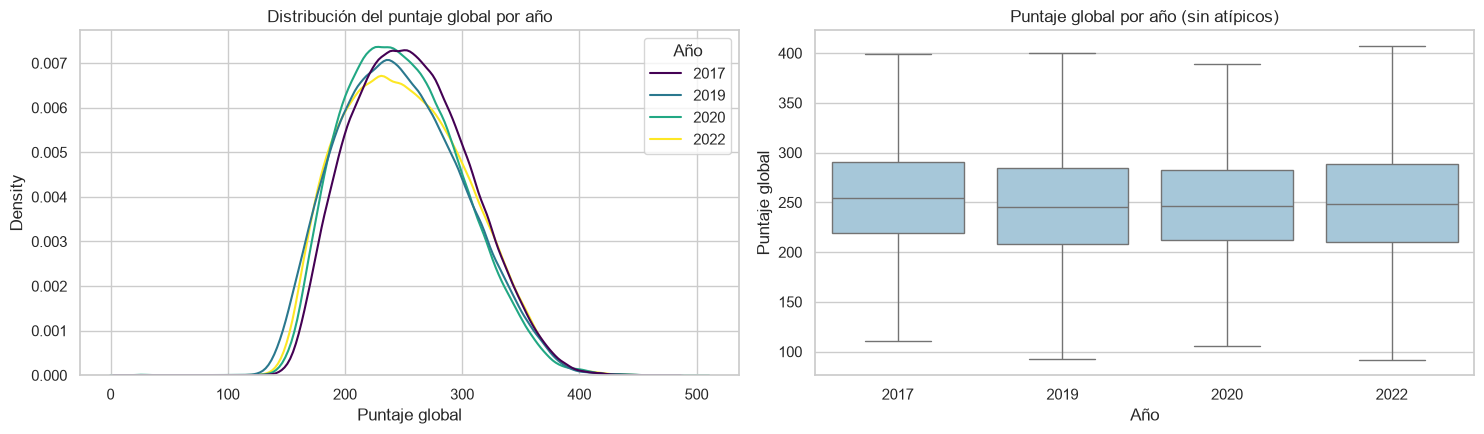

anio,n,media,desv,mediana
i64,u32,f64,f64,f64
2017,559277,256.6,49.3,254.0
2019,558747,247.8,52.5,245.0
2020,520226,249.6,49.5,246.0
2022,552837,251.4,52.6,248.0


In [24]:
pdf = df.select(["anio", "punt_global"]).to_pandas().rename(columns={"anio": "Año", "punt_global": "Puntaje global"})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.kdeplot(data=pdf, x="Puntaje global", hue="Año", common_norm=False, palette="viridis", ax=axes[0])
axes[0].set_title("Distribución del puntaje global por año")
sns.boxplot(data=pdf, x="Año", y="Puntaje global", color="#9ecae1", showfliers=False, ax=axes[1])
axes[1].set_title("Puntaje global por año (sin atípicos)")
plt.tight_layout(); guardar(fig, "01_distribucion_puntaje"); plt.show()

df.group_by("anio").agg(pl.len().alias("n"), pl.col("punt_global").mean().round(1).alias("media"),
                        pl.col("punt_global").std().round(1).alias("desv"),
                        pl.col("punt_global").median().alias("mediana")).sort("anio")

### 5.3 El hogar: estrato, educación de la madre, internet y computador

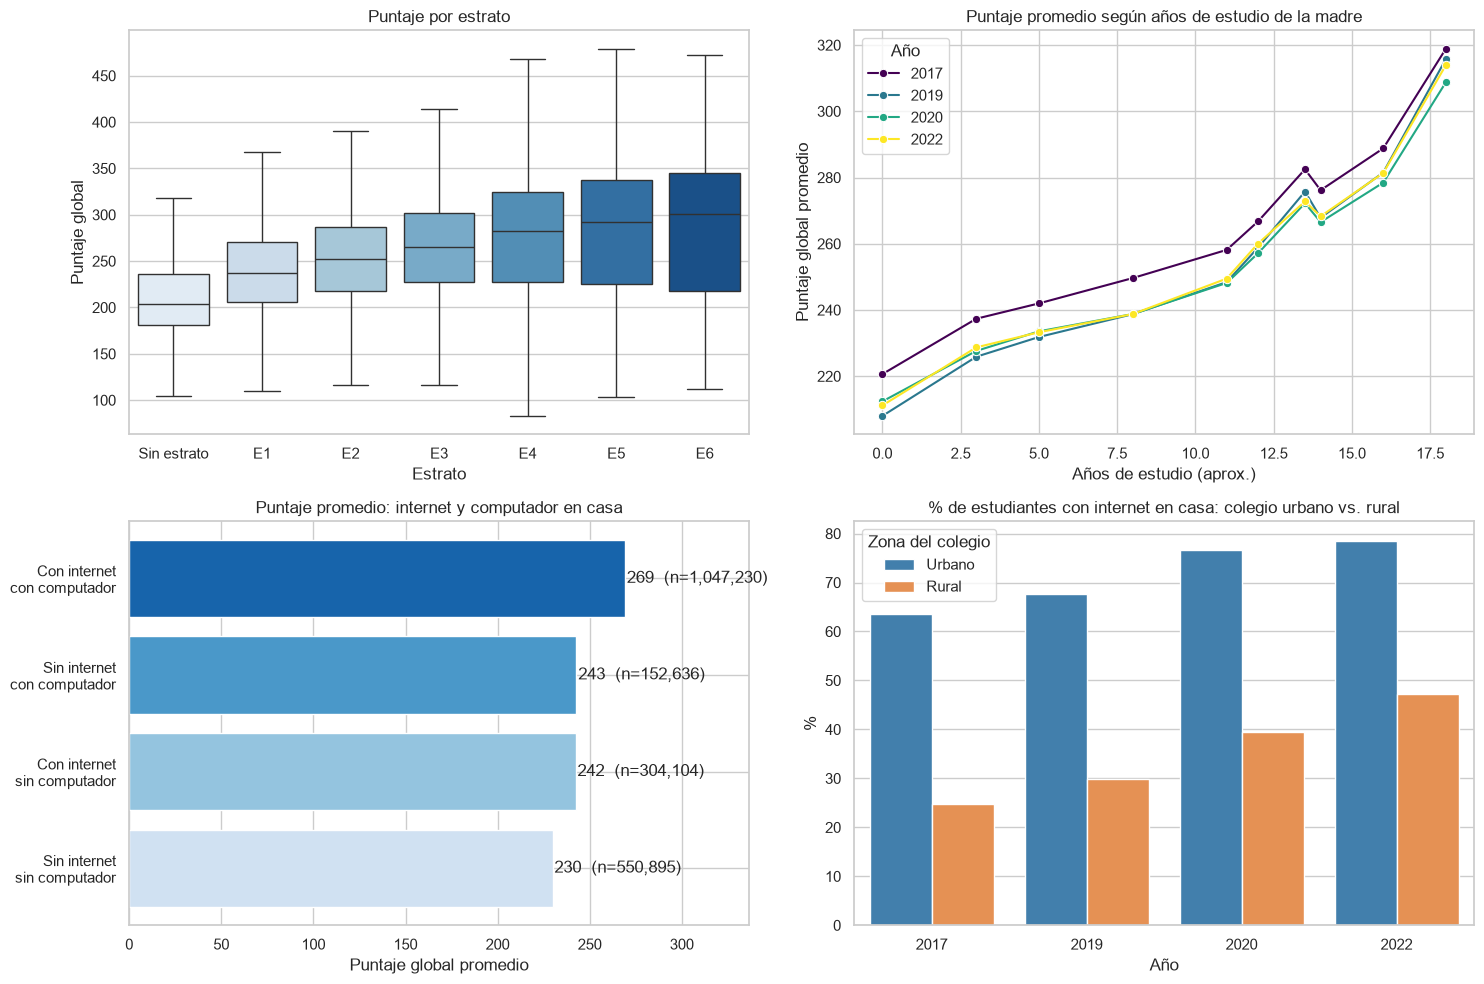

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

e = df.filter(pl.col("estrato").is_not_null()).select(["estrato", "punt_global"]).to_pandas()
e["estrato"] = e["estrato"].astype(int).map(lambda x: "Sin estrato" if x == 0 else f"E{x}")
sns.boxplot(data=e, x="estrato", y="punt_global", order=["Sin estrato"] + [f"E{i}" for i in range(1, 7)],
            palette="Blues", showfliers=False, ax=axes[0, 0])
axes[0, 0].set(title="Puntaje por estrato", xlabel="Estrato", ylabel="Puntaje global")

m = (df.filter(pl.col("educ_madre").is_not_null()).group_by(["anio", "educ_madre"])
     .agg(pl.col("punt_global").mean().alias("punt")).sort("educ_madre").to_pandas())
sns.lineplot(data=m.rename(columns={"anio": "Año"}), x="educ_madre", y="punt", hue="Año", marker="o", palette="viridis", ax=axes[0, 1])
axes[0, 1].set(title="Puntaje promedio según años de estudio de la madre", xlabel="Años de estudio (aprox.)", ylabel="Puntaje global promedio")

ic = (df.filter(pl.col("internet_casa").is_not_null() & pl.col("computador_casa").is_not_null())
      .group_by(["internet_casa", "computador_casa"]).agg(pl.col("punt_global").mean().alias("punt"), pl.len().alias("n"))
      .to_pandas())
ic["grupo"] = ic.apply(lambda r: f"{'Con' if r.internet_casa else 'Sin'} internet\n{'con' if r.computador_casa else 'sin'} computador", axis=1)
ic = ic.sort_values("punt")
axes[1, 0].barh(ic["grupo"], ic["punt"], color=sns.color_palette("Blues", 4))
for i, (p, n) in enumerate(zip(ic["punt"], ic["n"])):
    axes[1, 0].text(p + 1, i, f"{p:.0f}  (n={n:,})", va="center")
axes[1, 0].set(title="Puntaje promedio: internet y computador en casa", xlabel="Puntaje global promedio", xlim=(0, ic["punt"].max() * 1.25))

zona = (df.filter(pl.col("colegio_rural").is_not_null() & pl.col("internet_casa").is_not_null())
        .group_by(["anio", "colegio_rural"]).agg((pl.col("internet_casa").mean() * 100).alias("pct")).to_pandas())
zona["zona"] = zona["colegio_rural"].map({0.0: "Urbano", 1.0: "Rural"})
sns.barplot(data=zona.rename(columns={"anio": "Año"}), x="Año", y="pct", hue="zona", hue_order=["Urbano", "Rural"], palette=["#3182bd", "#fd8d3c"], ax=axes[1, 1])
axes[1, 1].set(title="% de estudiantes con internet en casa: colegio urbano vs. rural", ylabel="%")
axes[1, 1].legend(title="Zona del colegio")

plt.tight_layout(); guardar(fig, "02_hogar"); plt.show()

### 5.4 La brecha dentro de cada estrato
¿Tener internet en casa se asocia con más puntaje **incluso comparando estudiantes del mismo estrato**? (tabla Gold)

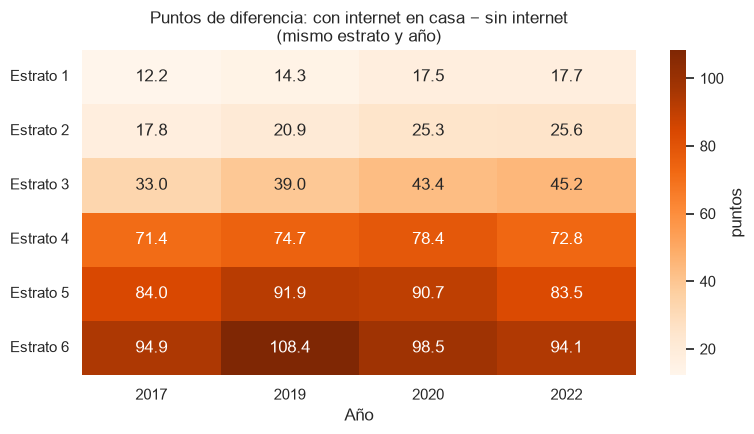

In [26]:
br = pd.read_parquet(GOLD / "brecha_estrato_internet")
br = br[br.estrato > 0]
piv = br.pivot_table(index=["anio", "estrato"], columns="internet_casa", values="punt_prom")
piv["brecha"] = piv[1.0] - piv[0.0]
tabla = piv["brecha"].unstack("anio")
tabla.index = [f"Estrato {int(i)}" for i in tabla.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="Oranges", cbar_kws={"label": "puntos"}, ax=ax)
ax.set_title("Puntos de diferencia: con internet en casa − sin internet\n(mismo estrato y año)")
ax.set(xlabel="Año", ylabel="")
plt.tight_layout(); guardar(fig, "03_brecha_estrato"); plt.show()

### 5.5 Evolución 2017 → 2022

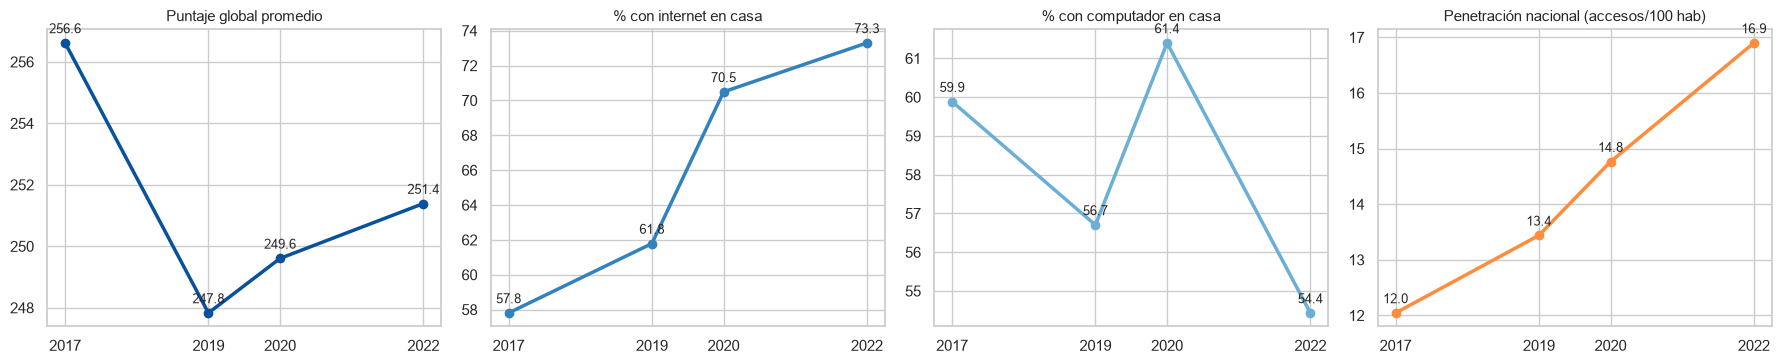

,Puntaje global promedio,% con internet en casa,% con computador en casa,Penetración nacional (accesos/100 hab)
anio,,,,
2017,256.60,57.80,59.90,12.00
2019,247.80,61.80,56.70,13.40
2020,249.60,70.50,61.40,14.80
2022,251.40,73.30,54.40,16.90


In [27]:
evo = (df.group_by("anio").agg(
        pl.col("punt_global").mean().alias("Puntaje global promedio"),
        (pl.col("internet_casa").mean() * 100).alias("% con internet en casa"),
        (pl.col("computador_casa").mean() * 100).alias("% con computador en casa"))
       .sort("anio").to_pandas().set_index("anio"))
evo_mun = (mun.groupby("anio").apply(lambda g: 100 * g.accesos.sum() / g.poblacion.sum())
           .rename("Penetración nacional (accesos/100 hab)"))
evo = evo.join(evo_mun)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col, c in zip(axes, evo.columns, ["#08519c", "#3182bd", "#6baed6", "#fd8d3c"]):
    ax.plot(evo.index, evo[col], marker="o", color=c, lw=2.5)
    ax.set_title(col, fontsize=11); ax.set_xticks(evo.index)
    for x, y in evo[col].items():
        ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=9)
plt.tight_layout(); guardar(fig, "04_evolucion"); plt.show()
evo.round(1)

2020 coincide con la pandemia (examen con fechas corridas y protocolos especiales); conviene leer sus cifras con cuidado.

### 5.6 Nivel municipal: conectividad vs. puntaje

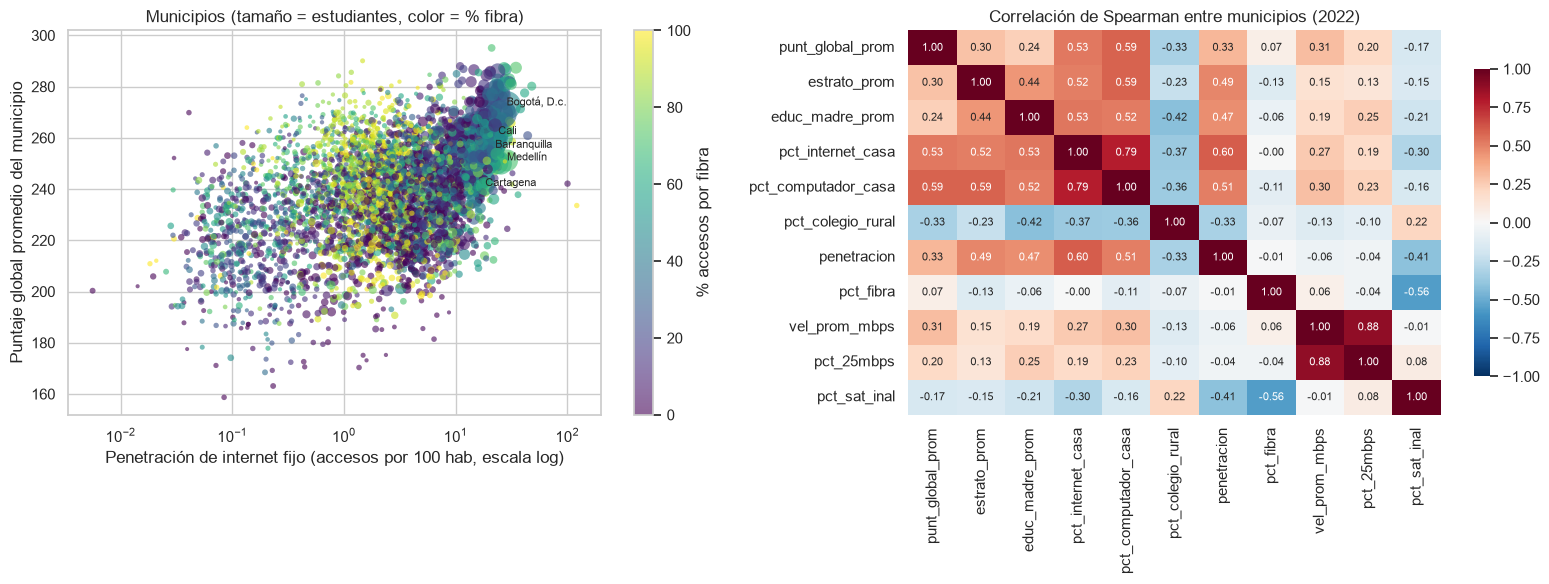

In [28]:
m30 = mun[(mun.n_estudiantes >= 30) & mun.penetracion.notna() & (mun.penetracion > 0)].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc = axes[0].scatter(m30.penetracion, m30.punt_global_prom, s=np.sqrt(m30.n_estudiantes) * 1.5,
                     c=m30.pct_fibra, cmap="viridis", alpha=0.6, edgecolor="none")
axes[0].set_xscale("log")
axes[0].set(xlabel="Penetración de internet fijo (accesos por 100 hab, escala log)",
            ylabel="Puntaje global promedio del municipio",
            title="Municipios (tamaño = estudiantes, color = % fibra)")
plt.colorbar(sc, ax=axes[0], label="% accesos por fibra")
for _, r in m30.query("anio == 2022").nlargest(5, "n_estudiantes").iterrows():
    axes[0].annotate(str(r.municipio), (r.penetracion, r.punt_global_prom), fontsize=8)

cols = ["punt_global_prom", "estrato_prom", "educ_madre_prom", "pct_internet_casa", "pct_computador_casa",
        "pct_colegio_rural", "penetracion", "pct_fibra", "vel_prom_mbps", "pct_25mbps", "pct_sat_inal"]
corr = m30.query("anio == 2022")[cols].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1],
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
axes[1].set_title("Correlación de Spearman entre municipios (2022)")
plt.tight_layout(); guardar(fig, "05_municipal"); plt.show()

Las variables de conectividad municipal están muy correlacionadas con el perfil socioeconómico del municipio (estrato y educación promedio, % de hogares con internet): el internet municipal **funciona en parte como un indicador de desarrollo**. Por eso la pregunta clave no es si se correlaciona con el puntaje (sí lo hace), sino si aporta **algo más** que las variables del hogar. Eso se mide en la sección 8.

## 6. Tipologías digitales de municipios (K-Means)
Agrupamos los municipios de 2022 según su perfil de conectividad (las 5 variables de MinTIC, estandarizadas; penetración y velocidad en log).
El silhouette es parecido entre k = 2 y k = 6, así que elegimos **k = 4** por interpretabilidad.

In [29]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

m22 = mun[(mun.anio == 2022)].dropna(subset=sb.VARS_MUNICIPIO + ["lat"]).copy()
X = m22[sb.VARS_MUNICIPIO].assign(penetracion=np.log1p(m22.penetracion), vel_prom_mbps=np.log1p(m22.vel_prom_mbps))
Xs = StandardScaler().fit_transform(X)

sil = {k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=42).fit_predict(Xs)) for k in range(2, 8)}
print("Silhouette por k:", {k: round(v, 3) for k, v in sil.items()})

K = 4
km = KMeans(K, n_init=20, random_state=42).fit(Xs)
m22["cluster"] = km.labels_
# Nombre de cada grupo según su perfil (medianas)
med = m22.groupby("cluster")[sb.VARS_MUNICIPIO].median()
c_alta = med.penetracion.idxmax()
c_sat = med.drop(c_alta).pct_sat_inal.idxmax()
resto = med.drop([c_alta, c_sat]).penetracion.sort_values().index
nombres_cl = {c_sat: "1. Satelital / inalámbrico", resto[0]: "2. Muy baja penetración",
              resto[1]: "3. Penetración media", c_alta: "4. Alta penetración"}
m22["tipologia"] = m22.cluster.map(nombres_cl)

perfil = (m22.groupby("tipologia").agg(
            municipios=("cod_mcpio", "size"), estudiantes=("n_estudiantes", "sum"),
            penetracion=("penetracion", "median"), pct_fibra=("pct_fibra", "median"),
            vel_prom_mbps=("vel_prom_mbps", "median"), pct_sat_inal=("pct_sat_inal", "median"),
            pct_internet_casa=("pct_internet_casa", "median"),
            punt_global=("punt_global_prom", lambda s: np.average(s, weights=m22.loc[s.index, "n_estudiantes"]))))
perfil.round(1)

Silhouette por k: {2: 0.363, 3: 0.353, 4: 0.344, 5: 0.345, 6: 0.333, 7: 0.306}


,municipios,estudiantes,penetracion,pct_fibra,vel_prom_mbps,pct_sat_inal,pct_internet_casa,punt_global
tipologia,,,,,,,,
1. Satelital / inalámbrico,260,42310,1.70,11.50,12.60,81.90,45.70,227.50
2. Muy baja penetración,211,21000,0.40,63.60,29.30,33.30,46.20,233.90
3. Penetración media,489,114762,4.60,71.60,10.50,8.50,53.80,233.30
4. Alta penetración,152,374673,17.10,50.20,87.20,5.30,79.70,260.60


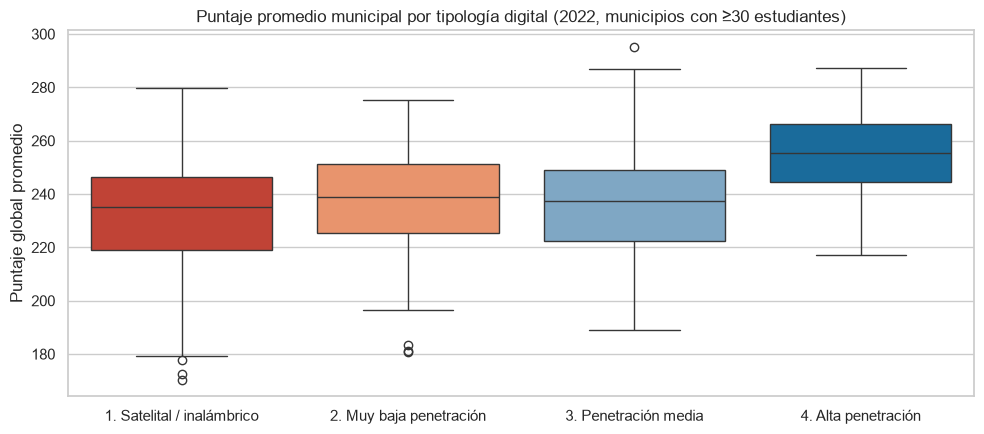

In [30]:
fig, ax = plt.subplots(figsize=(10, 4.5))
pal = dict(zip(sorted(nombres_cl.values()), ["#d7301f", "#fc8d59", "#74a9cf", "#0570b0"]))
sns.boxplot(data=m22[m22.n_estudiantes >= 30], x="tipologia", y="punt_global_prom", order=sorted(pal),
            palette=pal, ax=ax)
ax.set(title="Puntaje promedio municipal por tipología digital (2022, municipios con ≥30 estudiantes)",
       xlabel="", ylabel="Puntaje global promedio")
plt.tight_layout(); guardar(fig, "06_tipologias"); plt.show()

## 7. Mapas interactivos (Folium)
Como en el taller de datos geoespaciales: un mapa con capas que se activan desde el control de la esquina superior derecha.
- **Puntaje promedio 2022** (círculos de color; tamaño = estudiantes).
- **Penetración de internet 2022**.
- **Tipologías digitales** (K-Means).
- **HeatMap** de estudiantes **sin internet en casa**.

In [31]:
geo = m22.copy()
fig_mapa = folium.Figure(width="100%", height=650)
mapa = folium.Map(location=[4.6, -74.1], zoom_start=5, tiles=None).add_to(fig_mapa)
folium.TileLayer("Esri.WorldGrayCanvas", name="Mapa base (Esri)").add_to(mapa)   # sin API key, como en el taller 4
BOUNDS_COLOMBIA = [[-4.3, -79.1], [12.6, -66.8]]
mapa.fit_bounds(BOUNDS_COLOMBIA)

def capa_circulos(nombre, col, colores, fmt, show):
    vmin, vmax = geo[col].quantile([0.02, 0.98])
    cmap = LinearColormap(colores, vmin=vmin, vmax=vmax, caption=nombre)
    fg = folium.FeatureGroup(name=nombre, show=show)
    for _, r in geo.iterrows():
        folium.CircleMarker(
            location=[r.lat, r.lon], radius=min(2 + np.sqrt(r.n_estudiantes) / 10, 22),
            color=cmap(np.clip(r[col], vmin, vmax)), fill=True, fill_opacity=0.75, weight=0.5,
            popup=folium.Popup(f"<b>{r.municipio}</b> ({r.departamento})<br>"
                               f"Estudiantes: {r.n_estudiantes:,}<br>Puntaje: {r.punt_global_prom:.1f}<br>"
                               f"Penetración: {r.penetracion:.1f} / 100 hab<br>Fibra: {r.pct_fibra:.0f}%<br>"
                               f"Internet en casa: {r.pct_internet_casa:.0f}%<br>Tipología: {r.tipologia}", max_width=260),
            tooltip=f"{r.municipio}: {fmt(r[col])}").add_to(fg)
    fg.add_to(mapa)
    return cmap

cm1 = capa_circulos("Puntaje global promedio 2022", "punt_global_prom",
                    ["#d7301f", "#fdae61", "#ffffbf", "#a6d96a", "#1a9641"], lambda v: f"{v:.0f} pts", True)
cm2 = capa_circulos("Penetración internet 2022 (accesos/100 hab)", "penetracion",
                    ["#f7fbff", "#6baed6", "#08306b"], lambda v: f"{v:.1f}", False)

fg = folium.FeatureGroup(name="Tipologías digitales (K-Means)", show=False)
for _, r in geo.iterrows():
    folium.CircleMarker([r.lat, r.lon], radius=4, color=pal[r.tipologia], fill=True, fill_opacity=0.85,
                        weight=0, tooltip=f"{r.municipio}: {r.tipologia}").add_to(fg)
fg.add_to(mapa)

heat = geo.assign(w=geo.n_estudiantes * (1 - geo.pct_internet_casa / 100)).query("w > 0")
HeatMap(heat[["lat", "lon", "w"]].values.tolist(), name="HeatMap: estudiantes sin internet en casa",
        radius=14, blur=18, show=False).add_to(mapa)

cm1.add_to(mapa); cm2.add_to(mapa)
folium.LayerControl(collapsed=False, position="bottomleft").add_to(mapa)

# En VS Code y otros visores el mapa se crea antes de que su recuadro tenga tamaño:
# Leaflet calcula mal el zoom y no descarga el fondo. Se recalcula al terminar de cargar.
from branca.element import Element
nm = mapa.get_name()
mapa.get_root().script.add_child(Element(
    f"setTimeout(function() {{ {nm}.invalidateSize(); {nm}.fitBounds({BOUNDS_COLOMBIA}); }}, 400);"))
mapa.save(FIGS / "mapa_saber11_internet.html")
print(f"Mapa guardado en {FIGS / 'mapa_saber11_internet.html'} (ábralo en el navegador para verlo en pantalla completa)")
fig_mapa

Mapa guardado en resultados/mapa_saber11_internet.html (ábralo en el navegador para verlo en pantalla completa)


## 8. Modelos: ¿cuánto aporta el internet municipal?
Tres especificaciones (todas con efectos fijos de año):
1. **Solo hogar**: estrato, sin estrato, educación madre y padre, internet y computador en casa.
2. **Solo internet municipal**: penetración, % fibra, velocidad, % ≥25 Mbps, % satelital/inalámbrico.
3. **Hogar + internet municipal**.

Dos modelos: **regresión lineal** (interpretable) y **gradient boosting** (captura no linealidades). Métrica: R² en datos de prueba (25%).

**Techo municipal**: el R² que se lograría conociendo el puntaje promedio exacto de cada municipio-año. Ninguna variable medida a nivel municipal puede superar ese valor, porque todos los estudiantes de un mismo municipio reciben el mismo valor.

In [32]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

@track_performance("9_muestra_spark_a_pandas")
def muestra():
    return (spark.read.parquet(str(SILVER / "estudiantes"))
            .sample(fraction=0.2, seed=42).toPandas())
d = muestra()
anios_dum = pd.get_dummies(d.anio, prefix="anio", drop_first=True, dtype=float)
d = pd.concat([d, anios_dum], axis=1); V_ANIO = list(anios_dum.columns)
tr, te = train_test_split(d, test_size=0.25, random_state=42)
print(f"Muestra: {len(d):,} estudiantes (train {len(tr):,} / test {len(te):,})")

prom = tr.groupby(["cod_mcpio", "anio"]).punt_global.mean().rename("prom")
techo = r2_score(te.punt_global, te.join(prom, on=["cod_mcpio", "anio"])["prom"].fillna(tr.punt_global.mean()))

SPECS = {"Solo hogar": sb.VARS_HOGAR + V_ANIO,
         "Solo internet municipal": sb.VARS_MUNICIPIO + V_ANIO,
         "Hogar + internet municipal": sb.VARS_HOGAR + sb.VARS_MUNICIPIO + V_ANIO}
MODELOS = {"Lineal": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
           "Boosting": lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=42)}

@track_performance("9_entrenar_6_modelos")
def entrenar():
    filas, fit = [], {}
    for nm, ctor in MODELOS.items():
        for ns, cols in SPECS.items():
            mdl = ctor().fit(tr[cols], tr.punt_global)
            filas.append({"modelo": nm, "especificacion": ns, "R2": r2_score(te.punt_global, mdl.predict(te[cols]))})
            fit[(nm, ns)] = mdl
    return pd.DataFrame(filas), fit
res, ajustados = entrenar()
tabla_r2 = res.pivot(index="especificacion", columns="modelo", values="R2").loc[list(SPECS)]
print(f"Techo municipal (R² máximo de cualquier variable municipal): {techo:.3f}")
tabla_r2.map(lambda v: f"{v:.3f}")

[METRIC] 9_muestra_spark_a_pandas               | Time:    1.14s | RAM delta: +0.28 GB
Muestra: 438,236 estudiantes (train 328,677 / test 109,559)


[METRIC] 9_entrenar_6_modelos                   | Time:    9.89s | RAM delta: -0.51 GB
Techo municipal (R² máximo de cualquier variable municipal): 0.136


modelo,Boosting,Lineal
especificacion,,
Solo hogar,0.255,0.192
Solo internet municipal,0.133,0.084
Hogar + internet municipal,0.299,0.206


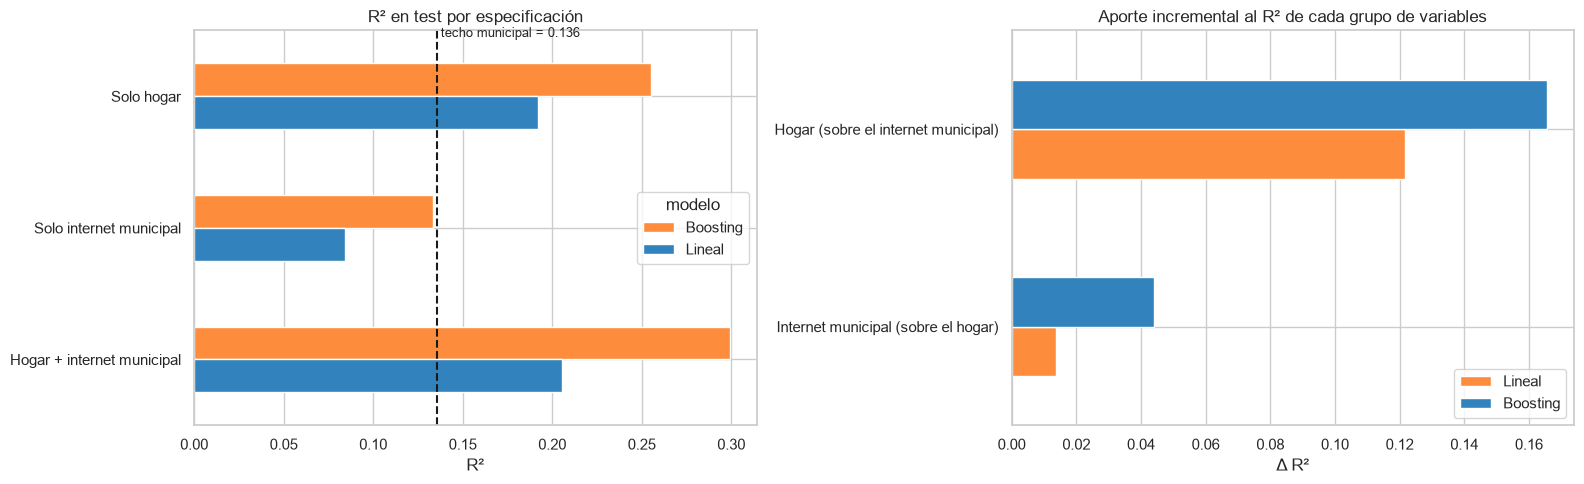

,Lineal,Boosting
Internet municipal (sobre el hogar),+0.014,+0.044
Hogar (sobre el internet municipal),+0.122,+0.166


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
tabla_r2.plot.barh(ax=axes[0], color=["#fd8d3c", "#3182bd"])
axes[0].axvline(techo, ls="--", c="k"); axes[0].text(techo, -0.45, f" techo municipal = {techo:.3f}", fontsize=9)
axes[0].set(title="R² en test por especificación", xlabel="R²", ylabel=""); axes[0].invert_yaxis()

r = res.set_index(["modelo", "especificacion"]).R2
aporte = pd.DataFrame({m: {"Internet municipal (sobre el hogar)": r[(m, "Hogar + internet municipal")] - r[(m, "Solo hogar")],
                           "Hogar (sobre el internet municipal)": r[(m, "Hogar + internet municipal")] - r[(m, "Solo internet municipal")]}
                       for m in MODELOS})
aporte.plot.barh(ax=axes[1], color=["#fd8d3c", "#3182bd"])
axes[1].set(title="Aporte incremental al R² de cada grupo de variables", xlabel="Δ R²")
plt.tight_layout(); guardar(fig, "07_r2_modelos"); plt.show()
aporte.map(lambda v: f"{v:+.3f}")

### 8.1 Interpretación: coeficientes estandarizados e importancia por permutación

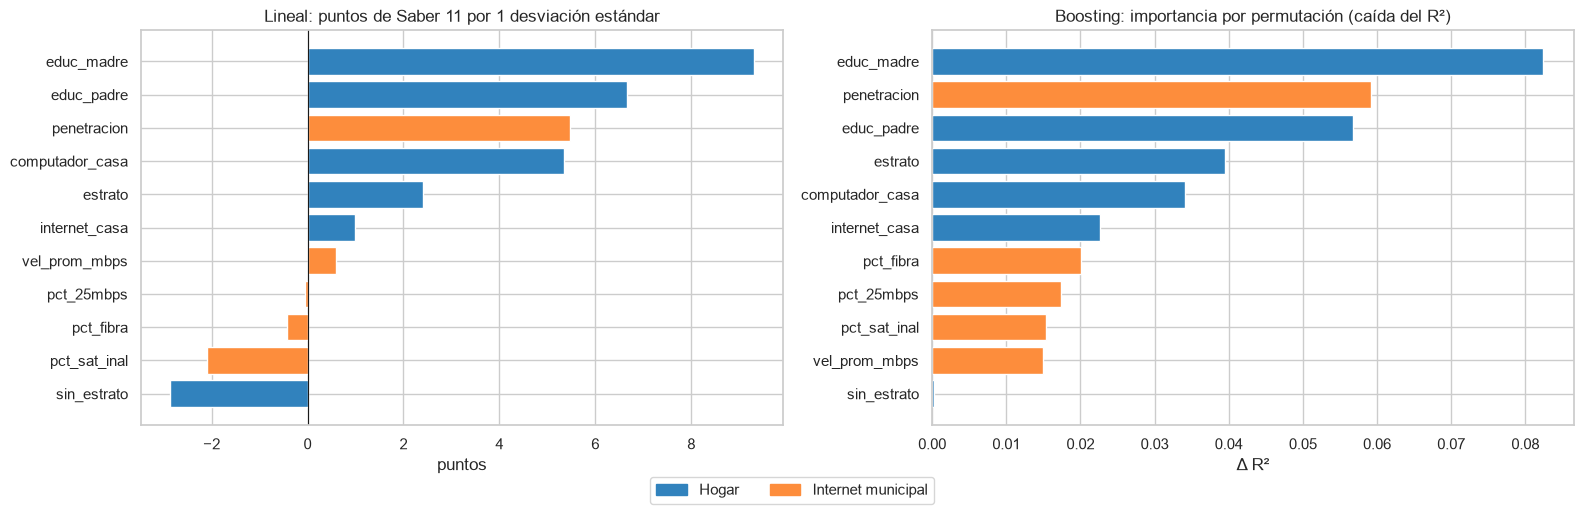

In [34]:
cols_full = SPECS["Hogar + internet municipal"]
lin = ajustados[("Lineal", "Hogar + internet municipal")]
coef = pd.Series(lin[-1].coef_, index=cols_full).drop(V_ANIO).sort_values()

gb = ajustados[("Boosting", "Hogar + internet municipal")]
sub = te.sample(20000, random_state=1)
pi = permutation_importance(gb, sub[cols_full], sub.punt_global, n_repeats=5, random_state=42, scoring="r2")
imp = pd.Series(pi.importances_mean, index=cols_full).drop(V_ANIO).sort_values()

grupo = lambda idx: ["#fd8d3c" if c in sb.VARS_MUNICIPIO else "#3182bd" for c in idx]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(coef.index, coef.values, color=grupo(coef.index)); axes[0].axvline(0, c="k", lw=0.8)
axes[0].set(title="Lineal: puntos de Saber 11 por 1 desviación estándar", xlabel="puntos")
axes[1].barh(imp.index, imp.values, color=grupo(imp.index))
axes[1].set(title="Boosting: importancia por permutación (caída del R²)", xlabel="Δ R²")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#3182bd", label="Hogar"), Patch(color="#fd8d3c", label="Internet municipal")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); guardar(fig, "08_importancia"); plt.show()

### 8.2 El mismo modelo lineal, distribuido, con Spark MLlib
scikit-learn trabaja con una muestra en memoria. Spark MLlib entrena **con los 2,2 M de estudiantes** repartidos en particiones: es el camino cuando los datos no caben en un solo computador.

In [35]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.regression import LinearRegression as SparkLR
from pyspark.ml.evaluation import RegressionEvaluator

full = spark.read.parquet(str(SILVER / "estudiantes"))
DUM_ANIO = [f"anio_{a}" for a in ANIOS[1:]]
for a in ANIOS[1:]:
    full = full.withColumn(f"anio_{a}", (F.col("anio") == a).cast("double"))   # efectos fijos de año
train_s, test_s = full.randomSplit([0.75, 0.25], seed=42)
ev = RegressionEvaluator(labelCol="punt_global", predictionCol="prediction", metricName="r2")

@track_performance("10_spark_mllib_3_modelos")
def mllib():
    out = {}
    for ns, cols in {"Solo hogar": sb.VARS_HOGAR, "Solo internet municipal": sb.VARS_MUNICIPIO,
                     "Hogar + internet municipal": sb.VARS_HOGAR + sb.VARS_MUNICIPIO}.items():
        imp_cols = [f"{c}_imp" for c in cols]
        pipe = Pipeline(stages=[
            Imputer(inputCols=cols, outputCols=imp_cols, strategy="median"),
            VectorAssembler(inputCols=imp_cols + DUM_ANIO, outputCol="features"),
            SparkLR(featuresCol="features", labelCol="punt_global")])
        out[ns] = ev.evaluate(pipe.fit(train_s).transform(test_s))
    return pd.Series(out, name="R2 Spark MLlib (100% datos)")

r2_mllib = mllib()
pd.concat([tabla_r2["Lineal"].rename("R2 sklearn (muestra 20%)"), r2_mllib], axis=1).map(lambda v: f"{v:.3f}")

[METRIC] 10_spark_mllib_3_modelos               | Time:   25.06s | RAM delta: +0.14 GB


,R2 sklearn (muestra 20%),R2 Spark MLlib (100% datos)
Solo hogar,0.192,0.189
Solo internet municipal,0.084,0.086
Hogar + internet municipal,0.206,0.204


El R² con todos los datos coincide con el de la muestra: la muestra del 20% es representativa y las conclusiones no dependen del muestreo.

## 9. MongoDB: la Gold como documentos geoespaciales
Se carga la Gold municipal como documentos GeoJSON, se crea un índice `2dsphere` y se consulta con *aggregation pipelines* (como en el taller 4).

**Conexión:** si hay un `MONGO_CONN_STRING` en el archivo `.env` se usa MongoDB Atlas; si no, se usa un MongoDB local en Docker:
```bash
docker run -d --name pbd-mongo -p 27017:27017 mongo:7   # la primera vez
docker start pbd-mongo                                   # las siguientes
```

In [36]:
from dotenv import load_dotenv
load_dotenv()
ATLAS_URI = os.getenv("MONGO_CONN_STRING")

import certifi
from pymongo import MongoClient, GEOSPHERE
from pymongo.server_api import ServerApi

def conectar_mongo():
    if ATLAS_URI:
        client = MongoClient(ATLAS_URI, server_api=ServerApi("1"), serverSelectionTimeoutMS=10000,
                             tls=True, tlsCAFile=certifi.where())
        destino = "MongoDB Atlas"
    else:
        client = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=5000)
        destino = "MongoDB local (Docker, localhost:27017)"
    try:
        client.admin.command("ping")
        print(f"Conectado a {destino}, versión {client.server_info()['version']}")
        return client
    except Exception as e:
        print(f"No se pudo conectar a {destino}: {type(e).__name__}")
        print("Inicia el contenedor con `docker start pbd-mongo` o define MONGO_CONN_STRING en .env")
        return None

client = conectar_mongo()
if client is not None:
    coll = client["saber11"]["municipios"]

    docs = []
    for r in mun.dropna(subset=["lat", "lon"]).to_dict("records"):
        doc = {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in r.items() if k not in ("lat", "lon")}
        doc["anio"] = int(doc["anio"]); doc["n_estudiantes"] = int(doc["n_estudiantes"])
        doc["location"] = {"type": "Point", "coordinates": [r["lon"], r["lat"]]}
        docs.append(doc)

    @track_performance("11_mongo_carga")
    def cargar_mongo():
        coll.delete_many({}); coll.insert_many(docs); coll.create_index([("location", GEOSPHERE)])
    cargar_mongo()
    print(f"{coll.count_documents({}):,} documentos en saber11.municipios")

    # Pipeline 1: departamentos 2022 (se calcula en el servidor)
    p1 = [{"$match": {"anio": 2022, "departamento": {"$ne": None}}},
          {"$group": {"_id": "$departamento",
                      "estudiantes": {"$sum": "$n_estudiantes"},
                      "puntos": {"$sum": {"$multiply": ["$punt_global_prom", "$n_estudiantes"]}},
                      "penetracion_mediana": {"$median": {"input": "$penetracion", "method": "approximate"}}}},
          {"$project": {"_id": 0, "departamento": "$_id", "estudiantes": 1, "penetracion_mediana": 1,
                        "punt_prom": {"$round": [{"$divide": ["$puntos", "$estudiantes"]}, 1]}}},
          {"$sort": {"punt_prom": 1}}, {"$limit": 8}]
    print("\nDepartamentos con menor puntaje (2022):")
    display(pd.DataFrame(coll.aggregate(p1)))

    # Pipeline 2: consulta geoespacial, municipios a menos de 100 km de Bogotá
    p2 = [{"$geoNear": {"near": {"type": "Point", "coordinates": [-74.08, 4.61]}, "distanceField": "dist_m",
                        "maxDistance": 100_000, "query": {"anio": 2022}, "spherical": True}},
          {"$project": {"_id": 0, "municipio": 1, "dist_km": {"$round": [{"$divide": ["$dist_m", 1000]}, 0]},
                        "punt_global_prom": {"$round": ["$punt_global_prom", 1]},
                        "penetracion": {"$round": ["$penetracion", 1]}}},
          {"$sort": {"punt_global_prom": -1}}, {"$limit": 10}]
    print("Municipios a menos de 100 km de Bogotá con mayor puntaje (2022):")
    display(pd.DataFrame(coll.aggregate(p2)))
    client.close()

Conectado a MongoDB local (Docker, localhost:27017), versión 7.0.48


[METRIC] 11_mongo_carga                         | Time:    0.10s | RAM delta: +0.00 GB
4,461 documentos en saber11.municipios

Departamentos con menor puntaje (2022):


,estudiantes,penetracion_mediana,departamento,punt_prom
0,4834,0.95,Chocó,206.00
1,437,0.18,Vaupés,213.80
2,800,0.14,Amazonas,216.40
3,618,0.20,Vichada,217.80
4,9924,1.83,La Guajira,221.50
5,387,1.22,Guainía,225.70
6,16979,2.04,Magdalena,227.70
7,1023,0.45,Guaviare,229.30


Municipios a menos de 100 km de Bogotá con mayor puntaje (2022):


,municipio,dist_km,punt_global_prom,penetracion
0,Chía,29.00,282.00,30.10
1,Cajicá,36.00,281.70,31.40
2,La Calera,19.00,278.00,25.20
3,Mosquera,19.00,277.10,27.00
4,Zipaquirá,49.00,274.70,21.80
5,Sopó,33.00,274.60,14.60
6,Tabio,38.00,273.30,18.50
7,"Bogotá, D.c.",35.00,272.60,28.60
8,Santa María,95.00,272.40,4.80
9,Cota,20.00,272.30,27.30


## 10. Tablero de observabilidad
Tiempo de cada paso del pipeline medido con `@track_performance`. En rojo las estrategias "lentas" de cada comparación (sort-merge join, sin caché, CSV), en verde sus alternativas optimizadas.

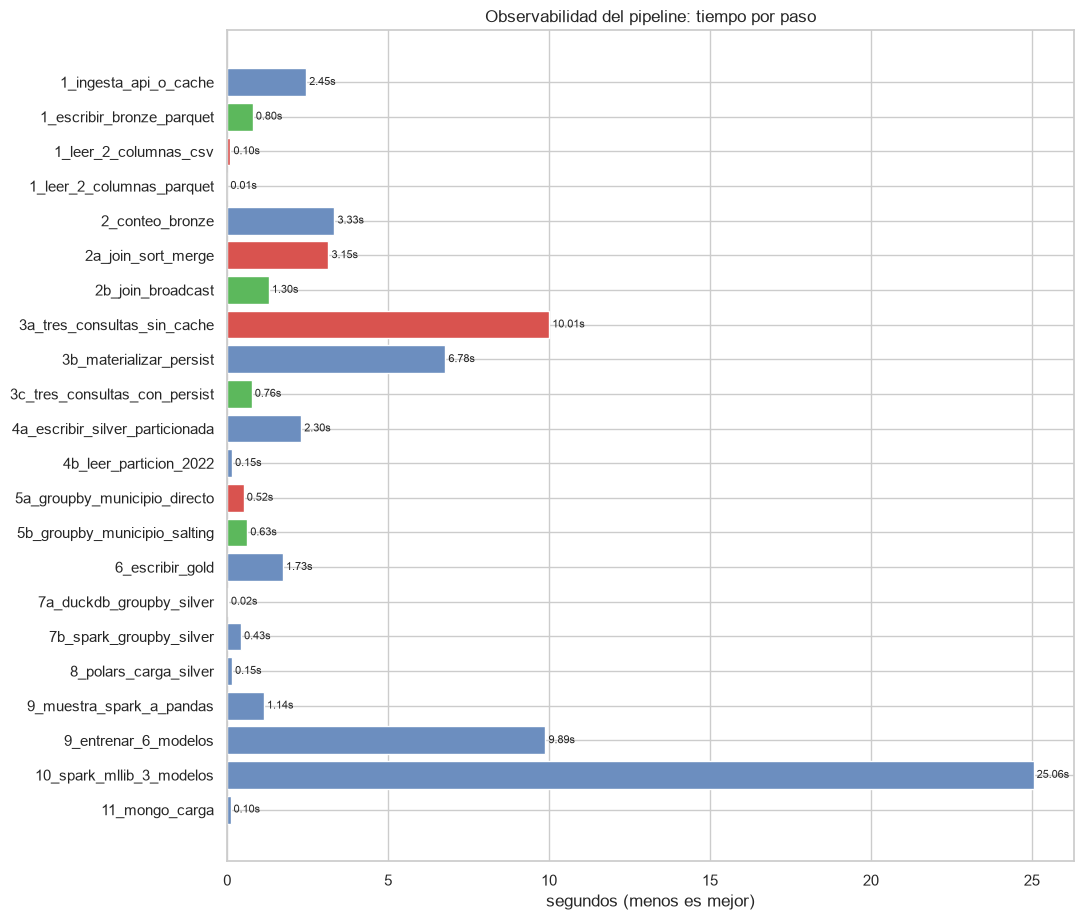

,operación,A,B,seg_A,seg_B,aceleración
0,Join con dimensión,Sort-merge,Broadcast,3.15,1.30,2.4x
1,3 consultas sobre la Silver,Sin caché,Con persist,10.01,0.76,13.1x
2,Leer 2 columnas (2022),CSV,Parquet,0.10,0.01,14.4x
3,GROUP BY estrato sobre la Silver,Spark,DuckDB,0.43,0.02,18.4x


In [37]:
pasos = list(pipeline_timings)
lentos = ("sort_merge", "sin_cache", "_csv", "directo")
rapidos = ("broadcast", "con_persist", "_parquet", "salting", "duckdb")
colores = ["#d9534f" if any(k in s for k in lentos) else "#5cb85c" if any(k in s for k in rapidos) else "#6c8ebf" for s in pasos]

fig, ax = plt.subplots(figsize=(11, 0.38 * len(pasos) + 1))
ax.barh(pasos[::-1], [pipeline_timings[p] for p in pasos][::-1], color=colores[::-1])
for i, v in enumerate([pipeline_timings[p] for p in pasos][::-1]):
    ax.text(v, i, f" {v:.2f}s", va="center", fontsize=8)
ax.set(title="Observabilidad del pipeline: tiempo por paso", xlabel="segundos (menos es mejor)")
plt.tight_layout(); guardar(fig, "09_observabilidad"); plt.show()

comparaciones = pd.DataFrame([
    ("Join con dimensión", "Sort-merge", "Broadcast", "2a_join_sort_merge", "2b_join_broadcast"),
    ("3 consultas sobre la Silver", "Sin caché", "Con persist", "3a_tres_consultas_sin_cache", "3c_tres_consultas_con_persist"),
    ("Leer 2 columnas (2022)", "CSV", "Parquet", "1_leer_2_columnas_csv", "1_leer_2_columnas_parquet"),
    ("GROUP BY estrato sobre la Silver", "Spark", "DuckDB", "7b_spark_groupby_silver", "7a_duckdb_groupby_silver"),
], columns=["operación", "A", "B", "ka", "kb"])
comparaciones["seg_A"] = comparaciones.ka.map(pipeline_timings)
comparaciones["seg_B"] = comparaciones.kb.map(pipeline_timings)
comparaciones["aceleración"] = (comparaciones.seg_A / comparaciones.seg_B).round(1).astype(str) + "x"
comparaciones.drop(columns=["ka", "kb"]).round(2)

In [38]:
silver.unpersist()
spark.stop()
print("Persistencia liberada y SparkSession detenida.")

Persistencia liberada y SparkSession detenida.


## 11. Conclusiones

### Sobre la pregunta
1. **El hogar explica mucho más que el municipio.** Con solo variables del hogar el R² es 0,192 (lineal) y 0,255 (boosting). Agregar el internet municipal suma apenas **+0,014** y **+0,044**. Lo que más pesa es la educación de la madre (+9,3 puntos por desviación estándar), la del padre (+6,6) y tener computador (+5,3).
2. **El internet municipal se correlaciona con el puntaje, pero sobre todo porque refleja el desarrollo del municipio.** En 2022, los municipios del quintil más conectado promedian 260 puntos y los del menos conectado 221. Pero la penetración también se correlaciona con el % de hogares con internet (ρ = 0,60), el estrato (0,49) y la educación de las madres (0,47).
3. **Techo municipal.** Ninguna variable municipal puede explicar más de R² = 0,136, el valor que da conocer el promedio exacto de cada municipio. El boosting con solo internet municipal llega a 0,133: está prácticamente **identificando al municipio**, no midiendo un efecto del internet. No se debe presentar como efecto causal.
4. **La brecha de internet en casa crece en los estratos bajos.** Comparando estudiantes del mismo estrato, tener internet en casa se asocia con 12 puntos más en estrato 1 en 2017 y 18 en 2022; en estrato 3, de 33 a 45. En los estratos 4 a 6 la diferencia es mucho mayor (70–108 puntos), pero allí los estudiantes *sin* internet son muy pocos y atípicos; no conviene leerla como efecto.
5. **La brecha rural se está cerrando, pero sigue siendo grande:** en 2022, el 47% de los estudiantes de colegios rurales tenía internet en casa, frente al 78% de los urbanos (en 2017: 25% vs. 63%).
6. **Tipologías digitales (K-Means, 2022):** 260 municipios dependen de conexiones satelitales o inalámbricas (82% de sus accesos) y tienen el puntaje más bajo (227,5). Los 152 municipios de alta penetración concentran el 68% de los estudiantes y promedian 260,6.

### Sobre las herramientas
| Técnica | Resultado en esta ejecución |
|---|---|
| Parquet vs. CSV | 88% menos espacio; leer 2 columnas ~15x más rápido (*column pruning*) |
| Broadcast join vs. sort-merge | 2–3x más rápido, sin shuffle de la tabla grande |
| `persist(MEMORY_AND_DISK)` | consultas repetidas ~10x más rápidas (`InMemoryTableScan`) |
| `partitionBy("anio")` | `PartitionFilters` lee solo la carpeta del año pedido; particiones balanceadas |
| Salting | mismo resultado exacto; repartió la llave caliente (Bogotá, 15,6% de los estudiantes) |
| DuckDB vs. Spark local | DuckDB ~20x más rápido para 2,2 M de filas: con datos que caben en un computador, un motor OLAP local gana; Spark se justifica cuando los datos o el cómputo crecen (MLlib entrenó con el 100% y obtuvo el mismo R² que la muestra) |
| Agregación en la API | se bajaron ~1.100 filas por año de internet en vez de ~190.000 |

Los tiempos cambian en cada ejecución; las proporciones se mantienen.

### Limitaciones
- **Población constante**: la penetración usa la población DANE 2023 para todos los años (aproximación). Belalcázar (Caldas) aparece con 121 accesos por 100 habitantes, probablemente por un error de reporte.
- **Velocidades**: la corrección kbps → Mbps es una regla heurística (valores > 1.000).
- **Asociación, no causalidad**: no hay diseño cuasi-experimental; el internet municipal está entrelazado con el desarrollo socioeconómico.
- **Años**: 2018 y 2021 no tienen calendario A en el consolidado; 2020 se presentó en pandemia.
- **Municipio de residencia** del estudiante para el cruce (se puede cambiar al del colegio con `cod_mcpio_colegio`).